# 04 · EDA de relaciones (niveles 2–3): etiquetas, línea base HT0, HT2, HT3, HP3, HF2, HF3 y HF4

**Objetivo.** Construir el panel de modelado (ticker × semana, solo datos ≤ t), decidir los parámetros (k, N) de la etiqueta de triple barrera, calibrar la línea base GBM (HT0), medir la asociación indicador → etiqueta (HT2), decidir qué indicadores se conservan (E2), revisar si la relación es estable entre regímenes (HT3), medir la dependencia del sector (HP3), el múltiplo relativo (HF2), la valoración con calidad (HF3, exploratoria) y la distancia al default de Merton (HF4), y resumir la cobertura de técnicas y el estado de todas las hipótesis.

**Punto del enunciado:** 6 (EDA bivariado y multivariado, niveles 2–3). **Hipótesis:** HT0, HT1 (preparada: la línea base y las etiquetas que usará el SVM), HT2, HT3, HT4 (barreras escaladas por σ), HF2, HF3, HF4, HP3, y el estado de las 14 hipótesis.

**Entradas (instantáneas):** `precios_semanales` (ajustado por splits y dividendos), `precios_semanales_sd` (solo splits), `splits`, `ratios_anuales` y `damodaran_pe`. **Salidas:** figuras en `entregables/entrega_1/assets` y el panel con las decisiones de (k, N) e indicadores.

**Nota metodológica.** Las observaciones semanales de un mismo ticker no son independientes (las ventanas de N semanas se solapan y las etiquetas se autocorrelacionan). Por eso los p-valores de Mann-Whitney son descriptivos y los intervalos se obtienen con *block bootstrap*. El lenguaje es de asociación, no causal.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from asistente import config, datos, edgar, fundamentales as fu, damodaran as dm, indicadores as ind, etiquetas as et, riesgo as rg, simulacion as sim
sns.set_theme(style="whitegrid"); pd.set_option("display.float_format", "{:.4f}".format)
config.DIR_ASSETS.mkdir(parents=True, exist_ok=True)

## 1. Panel de modelado
Una fila por ticker × semana. Los indicadores y σ (EWMA λ=0.94, conocida en t) usan solo datos ≤ t; las etiquetas miran hacia adelante y las últimas N semanas quedan censuradas (NaN). Se añade la etiqueta de retorno a 12 semanas, absoluta y relativa al ETF del sector.

In [2]:
sem = datos.cargar_snapshot("precios_semanales").sort_values(["ticker", "fecha"])
cl = sem.pivot(index="fecha", columns="ticker", values="close")
filas = []
for t in config.tickers():
    d = sem[sem.ticker == t].set_index("fecha")
    r = rg.log_retornos(d.close); sigma = rg.vol_ewma(r, 0.94, periodos=1)
    X = ind.tabla_indicadores(d.close, d.volume)
    for k in (1, 2):
        for n in (4, 12, 26):
            X[f"y_k{k}_n{n}"] = et.etiqueta_entrada(d.close, sigma, k_inf=k, k_sup=k, n=n).etiqueta
    etf = cl[config.ETF_SECTOR[config.industria_de(t)]]
    X["yret_abs12"] = et.etiqueta_retorno(d.close, 12)
    X["yret_rel12"] = et.etiqueta_retorno(d.close, 12, benchmark=etf)
    X["sigma"] = sigma; X["ticker"] = t; X["industria"] = config.industria_de(t)
    filas.append(X)
panel = pd.concat(filas).reset_index()
print(panel.shape, panel.fecha.min().date(), panel.fecha.max().date(), panel.ticker.nunique(), "tickers")
print(panel.isna().mean().round(3).to_dict())

(27326, 19) 2009-01-05 2026-10-12 30 tickers
{'fecha': 0.0, 'rsi14': 0.015, 'dist_sma20': 0.021, 'dist_sma50': 0.054, 'dist_ema20': 0.021, 'vol_rel20': 0.021, 'donchian20': 0.021, 'mom_12_1': 0.057, 'y_k1_n4': 0.005, 'y_k1_n12': 0.014, 'y_k1_n26': 0.03, 'y_k2_n4': 0.005, 'y_k2_n12': 0.014, 'y_k2_n26': 0.03, 'yret_abs12': 0.013, 'yret_rel12': 0.013, 'sigma': 0.001, 'ticker': 0.0, 'industria': 0.0}


## 2. Etiquetas: decisión de k y N
Para cada (k, N) se resume el balance de clases, las observaciones resueltas y censuradas, las ventanas no solapadas (`n_resueltas / N`, una cota de la muestra efectiva) y la ACF de la etiqueta en el rezago 1 (promedio por ticker; una ACF alta indica solapamiento entre ventanas vecinas).

In [3]:
def acf1(s):
    s = s.dropna()
    return s.autocorr(1) if len(s) > 30 else np.nan
filas = []
for k in (1, 2):
    for n in (4, 12, 26):
        c = f"y_k{k}_n{n}"; res = panel[c].notna()
        a = panel.groupby("ticker")[c].apply(acf1).mean()
        filas.append(dict(k=k, N=n, pct_clase1=panel[c].mean(), n_resueltas=int(res.sum()),
                          n_censuradas=int(panel[c].isna().sum()), n_no_solapadas=res.sum() / n, acf1_media=a))
tab_et = pd.DataFrame(filas); print(tab_et.to_string(index=False))
print("\nPor ticker (k=1, N=12): % clase 1 min/mediana/max:",
      panel.groupby("ticker")["y_k1_n12"].mean().agg(["min", "median", "max"]).round(3).to_dict())
bal = pd.DataFrame({"retorno_abs_12": panel.yret_abs12.agg(["mean", "count"]),
                    "retorno_rel_ETF_12": panel.yret_rel12.agg(["mean", "count"])}).T
bal.columns = ["pct_clase1", "n"]; print("\nEtiquetas de retorno a 12 semanas:\n", bal)

 k  N  pct_clase1  n_resueltas  n_censuradas  n_no_solapadas  acf1_media
 1  4      0.1649        27176           150       6794.0000      0.5441
 1 12      0.1711        26936           390       2244.6667      0.7345
 1 26      0.1704        26516           810       1019.8462      0.8137
 2  4      0.0341        27176           150       6794.0000      0.5134
 2 12      0.0388        26936           390       2244.6667      0.7505
 2 26      0.0382        26516           810       1019.8462      0.7977

Por ticker (k=1, N=12): % clase 1 min/mediana/max: {'min': 0.101, 'median': 0.17, 'max': 0.302}

Etiquetas de retorno a 12 semanas:
                     pct_clase1          n
retorno_abs_12          0.6386 26966.0000
retorno_rel_ETF_12      0.5047 26966.0000


**Justificación (k, N).** Se elige **k = 1, N = 12**: con k = 1 la clase 1 es ≈17 % (suficiente para entrenar y evaluar), mientras con k = 2 cae a ≈3–4 % (muy pocos positivos por ticker); N = 12 deja ≈2 245 ventanas no solapadas, contra ≈1 020 de N = 26, y su ACF(1) (0.73) es menor que la de N = 26 (0.81). N = 4 tiene menos solapamiento (0.54) pero un horizonte de un mes, demasiado corto para un nivel de entrada. La etiqueta de retorno absoluto está desbalanceada hacia 1 (64 %, por la tendencia alcista de la muestra), mientras la relativa al ETF queda en ≈50 %; la etiqueta de triple barrera es la de interés porque describe el riesgo de entrada (HT1), no solo el signo.

**Lectura:** la tabla anterior muestra que la clase 1 ronda 17 % para k = 1 en los tres horizontes y 3–4 % para k = 2; la ACF(1) de la etiqueta crece con N (0.54, 0.73, 0.81 para k = 1) porque las ventanas vecinas comparten semanas, por lo que el tamaño de muestra efectivo es cercano al de ventanas no solapadas y no al de filas.

In [4]:
# Descomposición de las observaciones censuradas de la etiqueta (k = 1, N = 12) por causa
cl30 = cl[config.tickers()]
hor = (cl30.shift(-12).isna() & cl30.notna()).stack(); hor = hor[hor]
hor_idx = set(zip(hor.index.get_level_values("ticker"), hor.index.get_level_values("fecha")))
cen = panel[panel["y_k1_n12"].isna()]
es_hor = np.array([(t, f) in hor_idx for t, f in zip(cen.ticker, cen.fecha)])
sin_sigma = cen.sigma.isna().to_numpy()
n_hor, n_sig, n_otra = int(es_hor.sum()), int((sin_sigma & ~es_hor).sum()), int((~es_hor & ~sin_sigma).sum())
print(f"Censuradas de y_k1_n12: {len(cen)} (tabla de arriba: 390)")
print(f"  por horizonte (las últimas 12 semanas de cada ticker, 12 × 30): {n_hor}")
print(f"  sin σ por calentamiento (primera semana de cada ticker, sin retorno previo): {n_sig}")
print(f"  otras causas: {n_otra}  | suma: {n_hor + n_sig + n_otra}")
print("Censuradas por horizonte a N = 12 en nb02 §6:", int(sum(c_.shift(-12).isna().sum() for c_ in (cl30[t].dropna() for t in cl30))) )
assert n_hor + n_sig + n_otra == len(cen) == 390

Censuradas de y_k1_n12: 390 (tabla de arriba: 390)
  por horizonte (las últimas 12 semanas de cada ticker, 12 × 30): 360
  sin σ por calentamiento (primera semana de cada ticker, sin retorno previo): 30
  otras causas: 0  | suma: 390
Censuradas por horizonte a N = 12 en nb02 §6: 360


**Lectura (censura de la etiqueta, k = 1, N = 12):** de las 390 observaciones censuradas de la tabla, 360 son censura por horizonte (las últimas 12 semanas de cada uno de los 30 tickers, aún sin resolver) y 30 carecen de σ por calentamiento (la primera semana de cada ticker, sin retorno previo para la EWMA); no hay otras causas y 360 + 30 = 390. La cifra de nb02 §6 (360 a 12 semanas, 1.32 %) coincide con la causa de horizonte; el calentamiento de los indicadores (SMA50, momentum 12-1) no es censura de la etiqueta y se cuenta aparte en nb02. Las 390 filas se excluyen del análisis.

## 3. HT0: línea base GBM frente a la tasa empírica
Se compara, para cada (k, N), la probabilidad GBM incondicional de la etiqueta (sin deriva, `prob_triple_barrera_gbm`) con la tasa observada. La base se calcula con la σ mediana de cada **decil de σ** (10 000 trayectorias), no con una σ global.

In [5]:
panel["dec_sigma"] = pd.qcut(panel.sigma, 10, labels=False)  # deciles sobre todo el panel
cal = []
for k in (1, 2):
    for n in (4, 12, 26):
        c = f"y_k{k}_n{n}"; sub = panel[panel[c].notna()]
        glob_ = sim.prob_triple_barrera_gbm(sub.sigma.median(), k, k, n, n_sims=10000)
        cal.append(dict(k=k, N=n, dec="global", sigma_med=sub.sigma.median(), gbm=glob_, emp=sub[c].mean()))
        for d, g in sub.groupby("dec_sigma"):
            cal.append(dict(k=k, N=n, dec=int(d), sigma_med=g.sigma.median(),
                            gbm=sim.prob_triple_barrera_gbm(g.sigma.median(), k, k, n, n_sims=10000), emp=g[c].mean(), n=len(g)))
cal = pd.DataFrame(cal); cal["brecha_pp"] = 100 * (cal.emp - cal.gbm)
print(cal[cal.dec == "global"].drop(columns=["dec", "n"]).to_string(index=False))
dd = cal[cal.dec != "global"]
print("\nBrecha por decil (pp): media, mín, máx por (k,N)\n", dd.groupby(["k", "N"]).brecha_pp.agg(["mean", "min", "max"]))
print("\nk=1, N=12 por decil de σ:\n", dd[(dd.k == 1) & (dd.N == 12)][["dec", "sigma_med", "gbm", "emp", "brecha_pp", "n"]].to_string(index=False))

 k  N  sigma_med    gbm    emp  brecha_pp
 1  4     0.0332 0.2156 0.1649    -5.0712
 1 12     0.0332 0.2740 0.1711   -10.2928
 1 26     0.0331 0.2914 0.1704   -12.1012
 2  4     0.0332 0.0310 0.0341     0.3111
 2 12     0.0332 0.0359 0.0388     0.2933
 2 26     0.0331 0.0423 0.0382    -0.4059

Brecha por decil (pp): media, mín, máx por (k,N)
          mean      min     max
k N                           
1 4   -5.1958 -13.3163  0.1988
  12 -10.4622 -21.5076 -5.0295
  26 -12.4095 -25.5644 -5.8432
2 4    0.2692  -2.1359  2.5739
  12   0.2427  -3.6071  2.1778
  26  -0.5226  -4.7455  2.7997

k=1, N=12 por decil de σ:
 dec  sigma_med    gbm    emp  brecha_pp         n
  0     0.0180 0.2656 0.2063    -5.9286 2724.0000
  1     0.0218 0.2679 0.1805    -8.7355 2714.0000
  2     0.0251 0.2694 0.1902    -7.9154 2686.0000
  3     0.0282 0.2709 0.2206    -5.0295 2679.0000
  4     0.0314 0.2730 0.2131    -5.9891 2670.0000
  5     0.0349 0.2755 0.1738   -10.1716 2693.0000
  6     0.0388 0.2769 0.1828 

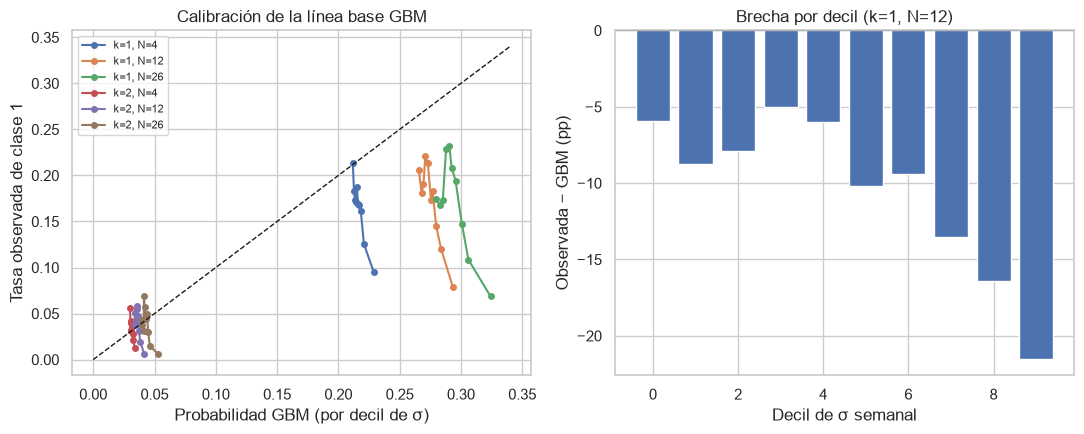

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for (k, n), g in dd.groupby(["k", "N"]):
    ax[0].plot(g.gbm, g.emp, "o-", ms=4, label=f"k={k}, N={n}")
lim = [0, dd[["gbm", "emp"]].max().max() * 1.05]; ax[0].plot(lim, lim, "k--", lw=1)
ax[0].set(xlabel="Probabilidad GBM (por decil de σ)", ylabel="Tasa observada de clase 1", title="Calibración de la línea base GBM")
ax[0].legend(fontsize=8)
g = dd[(dd.k == 1) & (dd.N == 12)]; ax[1].bar(g.dec, g.brecha_pp, color="C0")
ax[1].axhline(0, color="k", lw=.8); ax[1].set(xlabel="Decil de σ semanal", ylabel="Observada − GBM (pp)", title="Brecha por decil (k=1, N=12)")
fig.tight_layout(); fig.savefig(config.DIR_ASSETS / "nb04_calibracion_gbm.png", dpi=150, bbox_inches="tight"); plt.show()

**Lectura:** con k = 1 y N = 12 el GBM asigna 27.4 % a la clase 1 y la tasa observada es 17.1 %, el GBM sobreestima la clase 1 en 10.3 pp; la sobreestimación crece con el horizonte (5.1 pp para N = 4, 12.1 pp para N = 26). Por deciles de σ (N = 12) va de 5.0 pp a 21.5 pp: el GBM sobreestima más cuando σ es alta (decil 10: GBM 29.4 % vs. 7.8 % observado). Con k = 2 la línea base casi coincide (el GBM subestima en 0.3 pp en promedio por decil para N = 4 y 0.2 pp para N = 12). La asociación es compatible con que la volatilidad alta revierte (la barrera, ancha por σₜ, se toca menos) y con la deriva positiva de la muestra, ambas ignoradas por un GBM de σ constante y μ = 0.

**Justificación (HT0).** La caminata aleatoria sin deriva (μ = 0) **no está calibrada** para k = 1 y no es el rival justo (la línea base con deriva estimada solo con datos pasados se calcula en la celda siguiente): el SVM (HT1) debe compararse con el GBM *y* con la tasa empírica por decil de σ, o la mejora medida incluiría solo la corrección de este sesgo. En la práctica, σ y la tasa base por régimen de volatilidad serán rasgos del modelo. Esto complementa la conclusión de 03 (HT0 no apoyada como regla general por la regla literal: pasa en tecnología, 8 de 10, y la dependencia lineal en r es pequeña): la dirección es difícil de predecir, pero la *probabilidad* de tocar la barrera sí se aparta de la que implica un GBM.

**Síntesis (secciones 1–3).**
- Panel de 27 326 filas (30 tickers, 2009–2026); la muestra empieza en enero de 2009, así que la crisis 2008–09 queda cubierta solo desde su tramo final.
- Decisión: etiqueta de triple barrera con **k = 1, N = 12** (17 % de clase 1, ≈2 245 ventanas no solapadas).
- (Con μ = 0) la línea base GBM sobreestima la clase 1 en 10 pp para k = 1 y N = 12 (hasta 21 pp en σ alta); alimenta HT1: comparar contra GBM y contra la tasa empírica por decil de σ.

In [7]:
# Deriva estimada SOLO con datos pasados: media expansiva (>= 52 semanas) de los retornos log. semanales hasta t
lr = np.log(cl).diff()
mu_past = lr.expanding(min_periods=52).mean().stack().rename("mu_past").reset_index()
panel = panel.drop(columns=["mu_past"], errors="ignore").merge(mu_past, on=["fecha", "ticker"], how="left")
panel["dec_sigma"] = pd.qcut(panel.sigma, 10, labels=False)   # cortes sobre todo el panel (solo descriptivo; ver nota)
filas = []
for k, n in [(1, 4), (1, 12), (1, 26), (2, 12)]:
    c = f"y_k{k}_n{n}"; sub = panel[panel[c].notna() & panel.mu_past.notna()]
    for d, g in [("global", sub)] + list(sub.groupby("dec_sigma")):
        s = g.sigma.median(); m = g.mu_past.median()
        g0 = sim.prob_triple_barrera_gbm(s, k, k, n, mu=0.0, n_sims=10000)
        g1 = sim.prob_triple_barrera_gbm(s, k, k, n, mu=m + s ** 2 / 2, n_sims=10000)   # paso log medio = m
        filas.append(dict(k=k, N=n, dec=d, n=len(g), emp=g[c].mean(), gbm_mu0=g0, gbm_deriva=g1, mu_sem_med=m,
                          brecha_mu0_pp=100 * (g[c].mean() - g0), brecha_deriva_pp=100 * (g[c].mean() - g1)))
cal2 = pd.DataFrame(filas); gl = cal2[cal2.dec == "global"]; dd2 = cal2[cal2.dec != "global"]
print(gl[["k", "N", "n", "mu_sem_med", "emp", "gbm_mu0", "gbm_deriva", "brecha_mu0_pp", "brecha_deriva_pp"]].to_string(index=False))
print("\nBrecha media absoluta por decil (pp):\n", dd2.assign(a0=dd2.brecha_mu0_pp.abs(), a1=dd2.brecha_deriva_pp.abs()).groupby(["k", "N"])[["a0", "a1"]].mean().round(2))
print("\nk=1, N=12 por decil:\n", dd2[(dd2.k == 1) & (dd2.N == 12)][["dec", "emp", "gbm_mu0", "gbm_deriva", "brecha_mu0_pp", "brecha_deriva_pp"]].to_string(index=False))

 k  N     n  mu_sem_med    emp  gbm_mu0  gbm_deriva  brecha_mu0_pp  brecha_deriva_pp
 1  4 25646      0.0024 0.1693   0.2156      0.1697        -4.6295           -0.0395
 1 12 25406      0.0024 0.1781   0.2735      0.1857        -9.5353           -0.7553
 1 26 24986      0.0024 0.1789   0.2911      0.1693       -11.2160            0.9640
 2 12 25406      0.0024 0.0407   0.0359      0.0160         0.4838            2.4738

Brecha media absoluta por decil (pp):
           a0     a1
k N                
1 4   4.8900 2.9100
  12  9.9400 4.6700
  26 11.7200 5.8200
2 12  1.5000 2.7000

k=1, N=12 por decil:
    dec    emp  gbm_mu0  gbm_deriva  brecha_mu0_pp  brecha_deriva_pp
0.0000 0.2019   0.2656      0.1450        -6.3677            5.6923
1.0000 0.1813   0.2679      0.1609        -8.6622            2.0378
2.0000 0.1915   0.2694      0.1701        -7.7878            2.1422
3.0000 0.2273   0.2709      0.1762        -4.3574            5.1126
4.0000 0.2190   0.2730      0.1820        -5.4030   

**Lectura (línea base con deriva, solo datos pasados):** la deriva semanal se estima con la media expansiva de los retornos logarítmicos hasta t (mínimo 52 semanas; mediana 0.0024 por semana) y se pasa a `prob_triple_barrera_gbm` junto con la σ mediana de cada decil. Con la misma muestra (k = 1, N = 12, n = 25 406), el GBM sobreestima la clase 1 en 9.5 pp con μ = 0 y en 0.8 pp con deriva (0.186 del GBM frente a 0.178 observada); para N = 4 y N = 26 la sobreestimación pasa de 4.6 a 0.0 pp y de 11.2 pp a 1.0 pp de subestimación. Por decil de σ (N = 12) la brecha absoluta media baja de 9.9 a 4.7 pp, pero persiste la sobreestimación en σ alta (decil 10: 19.4 pp con μ = 0 y 12.3 pp con deriva) y aparece subestimación en σ baja (hasta 5.7 pp). Con k = 2 la deriva empeora el ajuste (el GBM subestima en 2.5 pp, frente a 0.5 pp con μ = 0), donde la clase 1 es rara (≈ 4 %). Parte de la brecha con μ = 0 era, entonces, deriva positiva de la muestra, y otra parte (la de σ alta) es una reversión que un GBM de σ constante no captura.

**Línea base que debe superar HT1.** El rival del SVM es el **GBM con deriva estimada solo con datos ≤ t** (caminata aleatoria con deriva) junto con la tasa empírica por decil de σ; el GBM con μ = 0 se conserva únicamente como referencia, porque su sobreestimación (≈ 10 pp) haría parecer mejor cualquier modelo que corrija la deriva. HT0 queda así: la caminata aleatoria no se apoya como regla general en nb03 §6 (solo en tecnología), y la probabilidad de la etiqueta se acerca a la del GBM con deriva en el agregado pero no por régimen de σ; la calibración formal de P_GBM se evalúa en la celda siguiente. **Nota:** los cortes de los deciles de σ se calculan aquí sobre todo el panel con fines descriptivos; si el decil se usa como rasgo de un modelo, sus cortes deben calcularse con datos ≤ t (por ejemplo, expansivos) para no introducir look-ahead.

In [8]:
# Calibración logística de P_GBM fila por fila (k = 1, N = 12): grilla σ × deriva pasada e interpolación
import time
from scipy.interpolate import RegularGridInterpolator
from asistente.validacion import calibracion_logistica, ic_bootstrap_fechas
t0 = time.time()
K_C, N_C, SIMS_C, REPS_C = 1, 12, 10000, 300
CAL = panel.loc[panel.y_k1_n12.notna() & panel.mu_past.notna() & panel.sigma.notna(),
                ["fecha", "ticker", "sigma", "mu_past", "dec_sigma", "y_k1_n12"]].reset_index(drop=True)
g_sig = np.unique(CAL.sigma.quantile(np.linspace(0, 1, 30)).to_numpy())    # 30 cuantiles de σ (incluye mín. y máx.)
g_mu = np.unique(CAL.mu_past.quantile(np.linspace(0, 1, 10)).to_numpy())   # 10 cuantiles de la deriva pasada
P0_g = np.array([sim.prob_triple_barrera_gbm(s, K_C, K_C, N_C, mu=0.0, n_sims=SIMS_C, semilla=0) for s in g_sig])
P1_g = np.array([[sim.prob_triple_barrera_gbm(s, K_C, K_C, N_C, mu=m + s ** 2 / 2, n_sims=SIMS_C, semilla=0) for m in g_mu] for s in g_sig])
s_c = CAL.sigma.clip(g_sig[0], g_sig[-1]).to_numpy(); m_c = CAL.mu_past.clip(g_mu[0], g_mu[-1]).to_numpy()
CAL["p_mu0"] = np.interp(s_c, g_sig, P0_g)
CAL["p_deriva"] = RegularGridInterpolator((g_sig, g_mu), P1_g, method="linear")(np.column_stack([s_c, m_c]))
print(f"Grilla: {len(g_sig)} nodos de σ ({g_sig[0]:.4f}–{g_sig[-1]:.4f}) × {len(g_mu)} de deriva ({g_mu[0]:.4f}–{g_mu[-1]:.4f}), {SIMS_C} trayectorias por nodo, semilla 0")
print("n filas:", len(CAL), "| fechas:", CAL.fecha.nunique())
print("Rango por fila de la P interpolada: p_mu0 %.4f–%.4f | p_deriva %.4f–%.4f" % (CAL.p_mu0.min(), CAL.p_mu0.max(), CAL.p_deriva.min(), CAL.p_deriva.max()))
# Control: media de la P interpolada frente a la P del decil (σ y deriva medianas, celda anterior)
chk = CAL.groupby("dec_sigma")[["p_mu0", "p_deriva"]].mean()
ref = dd2[(dd2.k == 1) & (dd2.N == 12)].set_index("dec")[["gbm_mu0", "gbm_deriva"]]
ref.index = ref.index.astype(int); chk.index = chk.index.astype(int)
print("\nControl por decil de σ (media de la P interpolada vs. P del decil):\n", chk.join(ref).round(4).to_string())
print("Global: media p_mu0 =", round(CAL.p_mu0.mean(), 4), "vs", round(gl[(gl.k == 1) & (gl.N == 12)].gbm_mu0.iloc[0], 4),
      "| media p_deriva =", round(CAL.p_deriva.mean(), 4), "vs", round(gl[(gl.k == 1) & (gl.N == 12)].gbm_deriva.iloc[0], 4),
      "| tasa observada =", round(CAL.y_k1_n12.mean(), 4))
# Regla de 4.4: calibrada si el IC 95 % de a incluye 0 y el de b incluye 1 (bootstrap por bloques de 12 fechas)
filas_c = []
for nom, col in [("GBM μ = 0", "p_mu0"), ("GBM con deriva ≤ t", "p_deriva")]:
    r = {"linea_base": nom}
    for par in ("a", "b"):
        est, lo_, hi_ = ic_bootstrap_fechas(CAL, lambda d, col=col, par=par: calibracion_logistica(d.y_k1_n12, d[col])[par],
                                            bloque=12, reps=REPS_C, semilla=42)
        r.update({par: est, f"{par}_IC_inf": lo_, f"{par}_IC_sup": hi_})
    r["IC_a_incluye_0"] = r["a_IC_inf"] <= 0 <= r["a_IC_sup"]; r["IC_b_incluye_1"] = r["b_IC_inf"] <= 1 <= r["b_IC_sup"]
    r["regla_4.4"] = "calibrada" if r["IC_a_incluye_0"] and r["IC_b_incluye_1"] else "no calibrada (sesgada)"
    filas_c.append(r)
tab_calib = pd.DataFrame(filas_c).set_index("linea_base")
print(f"\nCalibración logística logit P(y=1) = a + b·logit(P_GBM); IC 95 % por bloques de 12 fechas, {REPS_C} réplicas")
print(tab_calib.round(3).to_string())
print(f"Tiempo de la celda: {time.time() - t0:.0f} s")

Grilla: 30 nodos de σ (0.0106–0.1679) × 10 de deriva (-0.0135–0.0164), 10000 trayectorias por nodo, semilla 0
n filas: 25406 | fechas: 864
Rango por fila de la P interpolada: p_mu0 0.2618–0.3470 | p_deriva 0.0320–0.4110

Control por decil de σ (media de la P interpolada vs. P del decil):
            p_mu0  p_deriva  gbm_mu0  gbm_deriva
dec_sigma                                      
0         0.2653    0.1405   0.2656      0.1450
1         0.2678    0.1573   0.2679      0.1609
2         0.2695    0.1680   0.2694      0.1701
3         0.2710    0.1760   0.2709      0.1762
4         0.2731    0.1803   0.2730      0.1820
5         0.2752    0.1871   0.2754      0.1920
6         0.2771    0.1939   0.2769      0.1978
7         0.2799    0.1967   0.2798      0.2018
8         0.2842    0.2036   0.2839      0.2075
9         0.2941    0.2220   0.2920      0.2212
Global: media p_mu0 = 0.2752 vs 0.2735 | media p_deriva = 0.1812 vs 0.1857 | tasa observada = 0.1781



Calibración logística logit P(y=1) = a + b·logit(P_GBM); IC 95 % por bloques de 12 fechas, 300 réplicas
                         a  a_IC_inf  a_IC_sup       b  b_IC_inf  b_IC_sup  IC_a_incluye_0  IC_b_incluye_1               regla_4.4
linea_base                                                                                                                        
GBM μ = 0          -7.5700  -11.6040   -3.9410 -6.2160  -10.0990   -2.5800           False           False  no calibrada (sesgada)
GBM con deriva ≤ t -1.9830   -2.6720   -1.4290 -0.2940   -0.6410   -0.0110           False           False  no calibrada (sesgada)
Tiempo de la celda: 7 s


**Lectura (calibración logística de P_GBM, k = 1, N = 12):** P_GBM se calcula por fila interpolando una grilla de 30 nodos de σ (0.0106–0.1679) × 10 de deriva pasada (−0.0135 a 0.0164 por semana), con 10 000 trayectorias por nodo. Los cuantiles de la grilla se calculan sobre todo el panel solo para ubicar los puntos de interpolación (uso descriptivo): la P de cada fila sigue siendo función de σ_t y de la deriva pasada, ambas con datos ≤ t. El control coincide con la tabla por deciles: con μ = 0 la media interpolada es 0.2752 frente a 0.2735 global, y con deriva 0.1812 frente a 0.1857; por decil la mayor diferencia es 0.0051 (decil 8, índice 7 en la tabla, con deriva: 0.1967 frente a 0.2018).

Con μ = 0, la regresión logit P(y=1) = a + b·logit(P_GBM) da a = −7.570 (IC 95 % −11.604 a −3.941) y b = −6.216 (IC −10.099 a −2.580). Con deriva ≤ t, a = −1.983 (IC −2.672 a −1.429) y b = −0.294 (IC −0.641 a −0.011). En los dos casos el IC de a excluye 0 y el de b excluye 1, así que por la regla de 4.4 **P_GBM no está calibrada**, ni con μ = 0 ni con deriva.

Con μ = 0, P_GBM casi no varía entre filas (de 0.2618 a 0.3470), de modo que el rango de logit(P_GBM) es muy estrecho. Por eso, con μ = 0, a y b son artefactos de extrapolación y no se pueden leer por separado como sesgo o como pendiente; solo el veredicto y el signo de b son interpretables. Con deriva, la P por fila va de 0.0320 a 0.4110, un rango mucho más amplio, y b = −0.294 sí indica que el orden entre filas va en sentido contrario al del GBM. En los dos casos el signo de b es negativo: las filas con P_GBM más alta tienen una tasa observada más baja. El sesgo interpretable es la calibración en el agregado: la P media es 0.2752 con μ = 0 y 0.1812 con deriva, frente a una tasa observada de 0.1781. La deriva corrige el nivel medio pero no el orden entre filas. Los IC usan bloques de 12 fechas comunes (300 réplicas), de modo que conservan la dependencia entre tickers y entre ventanas solapadas.

In [9]:
# Regla literal de HT0, fila "calibración de P_GBM" (04_enfoque_analitico.md, 4.4)
# P_GBM está calibrada si el IC 95 % del intercepto a incluye 0 y el de la pendiente b incluye 1. Si no, el GBM es una línea base sesgada.
# La línea base que decide es el GBM con deriva <= t (la que usará HT1); el GBM con μ = 0 se muestra como referencia.
for nom, r in tab_calib.iterrows():
    print(f"{nom}: a = {r.a:.3f} (IC {r.a_IC_inf:.3f} a {r.a_IC_sup:.3f}) -> IC(a) incluye 0: {r.IC_a_incluye_0}; "
          f"b = {r.b:.3f} (IC {r.b_IC_inf:.3f} a {r.b_IC_sup:.3f}) -> IC(b) incluye 1: {r.IC_b_incluye_1} -> {r['regla_4.4']}")
CAL_OK = bool(tab_calib.loc["GBM con deriva ≤ t", "IC_a_incluye_0"] and tab_calib.loc["GBM con deriva ≤ t", "IC_b_incluye_1"])
ESTADO_HT0_CAL = "apoyada" if CAL_OK else "no apoyada"
print(f"REGLA HT0 (calibración): calibrada si IC(a) ∋ 0 e IC(b) ∋ 1 -> RESULTADO: GBM con deriva ≤ t {'calibrada' if CAL_OK else 'no calibrada'} "
      f"(sesgo en el agregado: P media {CAL.p_deriva.mean():.4f} frente a tasa observada {CAL.y_k1_n12.mean():.4f}) -> ESTADO HT0 (calibración): {ESTADO_HT0_CAL}")

GBM μ = 0: a = -7.570 (IC -11.604 a -3.941) -> IC(a) incluye 0: False; b = -6.216 (IC -10.099 a -2.580) -> IC(b) incluye 1: False -> no calibrada (sesgada)
GBM con deriva ≤ t: a = -1.983 (IC -2.672 a -1.429) -> IC(a) incluye 0: False; b = -0.294 (IC -0.641 a -0.011) -> IC(b) incluye 1: False -> no calibrada (sesgada)
REGLA HT0 (calibración): calibrada si IC(a) ∋ 0 e IC(b) ∋ 1 -> RESULTADO: GBM con deriva ≤ t no calibrada (sesgo en el agregado: P media 0.1812 frente a tasa observada 0.1781) -> ESTADO HT0 (calibración): no apoyada


**Lectura (regla literal de HT0, calibración de P_GBM):** la regla de 4.4 declara calibrada a P_GBM si el IC 95 % de a incluye 0 y el de b incluye 1. Con deriva ≤ t, el IC de a es −2.672 a −1.429 (no incluye 0) y el de b es −0.641 a −0.011 (no incluye 1); con μ = 0 tampoco (a: −11.604 a −3.941; b: −10.099 a −2.580). **Estado según la regla: HT0 (calibración) no apoyada**, es decir, P_GBM no está calibrada y es una línea base sesgada. El sesgo que se reporta, como pide la regla, es doble: en el agregado la deriva lo corrige casi por completo (P media 0.1812 frente a 0.1781 observada), pero el orden entre filas va al revés (b < 0), sobre todo por la sobreestimación en σ alta. El GBM con deriva ≤ t se mantiene como rival del SVM (HT1) porque es la caminata aleatoria con la información de t, y se complementa con la tasa empírica por decil de σ.

## 4. HT2: indicadores frente a la etiqueta (k = 1, N = 12)
Se analizan los 7 indicadores contra `y_k1_n12` (1 = el precio toca primero la barrera inferior). Se reportan la distribución por clase, la AUC univariada (probabilidad de que un indicador mayor corresponda a la clase 1; 0.5 = sin asociación) con IC 95 % por *block bootstrap* (bloques contiguos de N = 12 semanas por ticker, 500 réplicas), la información mutua y Mann-Whitney (descriptivo: las observaciones no son independientes).

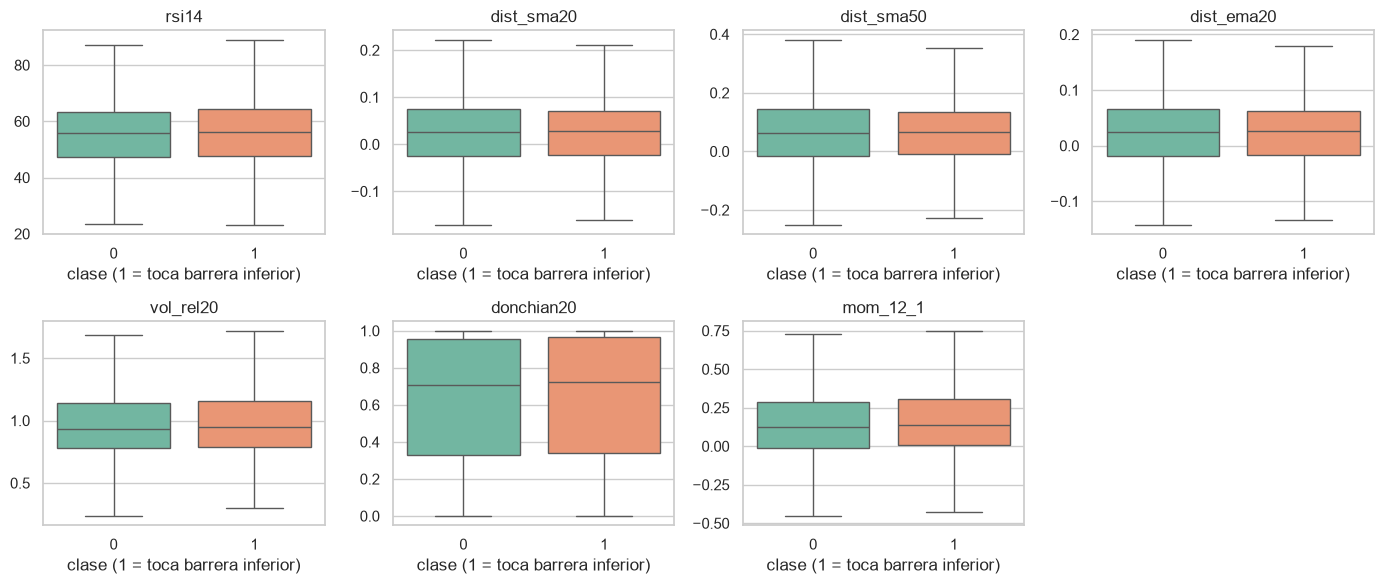

y_k1_n12    mediana clase 0  mediana clase 1
rsi14               55.7600          56.1931
dist_sma20           0.0258           0.0276
dist_sma50           0.0631           0.0648
dist_ema20           0.0254           0.0260
vol_rel20            0.9342           0.9488
donchian20           0.7047           0.7247
mom_12_1             0.1265           0.1401
n = 25406 | % clase 1 = 0.1781


In [10]:
from sklearn.metrics import roc_auc_score
from sklearn.feature_selection import mutual_info_classif
IND = ["rsi14", "dist_sma20", "dist_sma50", "dist_ema20", "vol_rel20", "donchian20", "mom_12_1"]
Y = "y_k1_n12"
D = panel.dropna(subset=IND + [Y]).reset_index(drop=True)
fig, axs = plt.subplots(2, 4, figsize=(14, 6)); axs = axs.ravel()
for a, c in zip(axs, IND):
    lo, hi = D[c].quantile([.01, .99])
    sns.boxplot(data=D.assign(clase=D[Y].astype(int)), x="clase", y=c, ax=a, showfliers=False, palette="Set2", hue="clase", legend=False)
    a.set(title=c, xlabel="clase (1 = toca barrera inferior)", ylabel="")
axs[-1].axis("off"); fig.tight_layout()
fig.savefig(config.DIR_ASSETS / "nb04_boxplots_indicadores.png", dpi=150, bbox_inches="tight"); plt.show()
print(D.groupby(Y)[IND].median().T.rename(columns={0.0: "mediana clase 0", 1.0: "mediana clase 1"}))
print("n =", len(D), "| % clase 1 =", round(D[Y].mean(), 4))

**Lectura:** las medianas por clase son casi idénticas (p. ej., RSI 55.8 en la clase 0 y 56.2 en la clase 1; distancia a la SMA20 2.58 % vs. 2.76 %), de modo que los boxplots se superponen casi por completo. La clase 1 tiene un volumen relativo y un momentum algo mayores (0.949 vs. 0.934 y 14.01 % vs. 12.65 %), y el techo de Donchian es ligeramente más alto (0.725 vs. 0.705), una dirección coherente con la sobreextensión solo de forma tenue.

In [11]:
N, REPS = 12, 500
rng = np.random.default_rng(42)
grupos = [g.index.to_numpy() for _, g in D.groupby("ticker")]
y = D[Y].to_numpy(); Xv = D[IND].to_numpy()
def remuestra():
    idx = []
    for g in grupos:
        nb_ = int(np.ceil(len(g) / N)); ini = rng.integers(0, len(g) - N + 1, nb_)
        idx.append(g[(ini[:, None] + np.arange(N)).ravel()[:len(g)]])
    return np.concatenate(idx)
auc0 = np.array([roc_auc_score(y, Xv[:, j]) for j in range(len(IND))])
boot = np.empty((REPS, len(IND)))
for b in range(REPS):
    ix = remuestra(); boot[b] = [roc_auc_score(y[ix], Xv[ix, j]) for j in range(len(IND))]
lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)
mi = mutual_info_classif(Xv, y, n_neighbors=5, random_state=0)
mw = [stats.mannwhitneyu(Xv[y == 1, j], Xv[y == 0, j]).pvalue for j in range(len(IND))]
tab_auc = pd.DataFrame({"indicador": IND, "AUC": auc0, "IC95_inf": lo, "IC95_sup": hi,
                        "excluye_0.5": (lo > .5) | (hi < .5), "info_mutua": mi, "p_MW (descriptivo)": mw}).set_index("indicador")
print(f"Block bootstrap: {REPS} réplicas, bloques de {N} semanas por ticker")
print(tab_auc.assign(**{"p_MW (descriptivo)": tab_auc["p_MW (descriptivo)"].map("{:.2e}".format)}))

Block bootstrap: 500 réplicas, bloques de 12 semanas por ticker
              AUC  IC95_inf  IC95_sup  excluye_0.5  info_mutua  \
indicador                                                        
rsi14      0.5126    0.4915    0.5316        False      0.0000   
dist_sma20 0.4986    0.4786    0.5162        False      0.0026   
dist_sma50 0.4964    0.4781    0.5166        False      0.0041   
dist_ema20 0.4964    0.4772    0.5145        False      0.0026   
vol_rel20  0.5137    0.5022    0.5270         True      0.0006   
donchian20 0.5072    0.4866    0.5242        False      0.0000   
mom_12_1   0.5130    0.4943    0.5351        False      0.0064   

           p_MW (descriptivo)  
indicador                      
rsi14                7.65e-03  
dist_sma20           7.64e-01  
dist_sma50           4.42e-01  
dist_ema20           4.44e-01  
vol_rel20            3.77e-03  
donchian20           1.27e-01  
mom_12_1             5.87e-03  


In [12]:
# IC alternativo: block bootstrap por FECHAS (todos los tickers comparten fechas, así que se remuestrean bloques de 12 fechas consecutivas conjuntamente)
REPS_F = 300; rng_f = np.random.default_rng(42)
fechas_u = np.sort(D.fecha.unique()); filas_f = D.groupby("fecha").indices
nbl = int(np.ceil(len(fechas_u) / N)); boot_f = np.empty((REPS_F, len(IND)))
for b in range(REPS_F):
    ini = rng_f.integers(0, len(fechas_u) - N + 1, nbl)
    ix = np.concatenate([filas_f[f] for i in ini for f in fechas_u[i:i + N]])
    boot_f[b] = [roc_auc_score(y[ix], Xv[ix, j]) for j in range(len(IND))]
lo_f, hi_f = np.percentile(boot_f, [2.5, 97.5], axis=0)
tab_auc["IC_fecha_inf"], tab_auc["IC_fecha_sup"] = lo_f, hi_f; tab_auc["excluye_0.5_fecha"] = (lo_f > .5) | (hi_f < .5)
auc_tk = pd.DataFrame({j: D.groupby("ticker").apply(lambda g, j=j: roc_auc_score(g[Y], g[j]) if g[Y].nunique() == 2 else np.nan) for j in IND})
tab_auc["AUC_mediana_por_ticker"] = auc_tk.median(); tab_auc["tickers_AUC>0.5"] = (auc_tk > .5).sum()
print(f"Block bootstrap por fechas: {REPS_F} réplicas, bloques de {N} fechas consecutivas (conjunto de tickers)")
print(tab_auc[["AUC", "IC95_inf", "IC95_sup", "IC_fecha_inf", "IC_fecha_sup", "excluye_0.5_fecha", "AUC_mediana_por_ticker", "tickers_AUC>0.5"]].round(4).to_string())
print("Tickers evaluados:", auc_tk.shape[0])

Block bootstrap por fechas: 300 réplicas, bloques de 12 fechas consecutivas (conjunto de tickers)
              AUC  IC95_inf  IC95_sup  IC_fecha_inf  IC_fecha_sup  excluye_0.5_fecha  AUC_mediana_por_ticker  tickers_AUC>0.5
indicador                                                                                                                    
rsi14      0.5126    0.4915    0.5316        0.4812        0.5484              False                  0.5283               21
dist_sma20 0.4986    0.4786    0.5162        0.4671        0.5313              False                  0.5107               16
dist_sma50 0.4964    0.4781    0.5166        0.4674        0.5363              False                  0.5166               17
dist_ema20 0.4964    0.4772    0.5145        0.4668        0.5281              False                  0.5167               16
vol_rel20  0.5137    0.5022    0.5270        0.4857        0.5418              False                  0.5269               19
donchian20 0.5072   

**Lectura:** las AUC univariadas están entre 0.496 y 0.514; solo `vol_rel20` (0.5137, IC 95 % 0.502–0.527) tiene un IC que excluye 0.5, y por margen mínimo. RSI (0.5126), momentum (0.5130) y Donchian (0.5072) apuntan en el sentido de la sobreextensión (valores altos con más retrocesos de entrada) pero sus IC por ticker incluyen 0.5; las distancias a medias móviles están en 0.496–0.499. La información mutua es ≤ 0.0064 nats para todos (máx. `mom_12_1`). **Robustez (IC por bloques de fechas).** El bootstrap por ticker ignora que todos los tickers comparten fechas (la dependencia transversal es fuerte: un mercado común). Al remuestrear bloques de 12 fechas consecutivas de todos los tickers a la vez (300 réplicas) los IC se ensanchan y **ningún indicador excluye 0.5**: `vol_rel20` pasa de 0.502–0.527 a 0.486–0.542, RSI queda en 0.481–0.548 y momentum en 0.473–0.564. La AUC mediana por ticker es 0.511–0.530 y entre 16 y 21 de los 30 tickers superan 0.5 (RSI 21; `vol_rel20`, Donchian y momentum 19), una inclinación pequeña y poco consistente. Mann-Whitney da p pequeños para RSI, `vol_rel20` y momentum (0.004–0.008), pero ese p-valor es descriptivo: las ventanas solapadas de un mismo ticker no son independientes y el criterio es el IC por bloques de fechas, el más conservador.

**Justificación (HT2).** La asociación univariada indicador–etiqueta va en el signo esperado para RSI, Donchian y momentum, pero es de ≈1 punto de AUC y, con el IC por bloques de fechas, ningún indicador excluye 0.5. El estado, que se fija con la regla literal de 4.4 más abajo (después del ajuste BH), es **no concluyente**: ningún indicador solo discrimina, y el valor, si existe, estaría en combinaciones y en la interacción con σ (HT1). Es una asociación, no una relación causal ni una señal operable por sí sola. La AUC es agregada sobre tickers con tasas base distintas (10–30 %), lo que puede mezclar efectos entre tickers.

In [13]:
# Benjamini-Hochberg sobre los p-valores de Mann-Whitney de los 7 indicadores (descriptivo: supone observaciones independientes)
from statsmodels.stats.multitest import multipletests
rech_bh, p_bh, _, _ = multipletests(tab_auc["p_MW (descriptivo)"], alpha=0.05, method="fdr_bh")
tab_auc["p_MW_BH (descriptivo)"] = p_bh; tab_auc["BH<0.05 (descriptivo)"] = rech_bh
tab_auc["sentido_AUC"] = np.where(tab_auc.AUC > .5, "AUC > 0.5", "AUC < 0.5")
print("Mann-Whitney con ajuste Benjamini-Hochberg (FDR 5 %, 7 pruebas); ambos p-valores son descriptivos")
print(tab_auc[["AUC", "sentido_AUC", "p_MW (descriptivo)", "p_MW_BH (descriptivo)", "BH<0.05 (descriptivo)", "excluye_0.5_fecha"]]
      .to_string(formatters={"p_MW (descriptivo)": "{:.2e}".format, "p_MW_BH (descriptivo)": "{:.2e}".format, "AUC": "{:.4f}".format}))
print("Indicadores que cumplen las dos condiciones de 4.4 (IC por fechas excluye 0.5 y p_BH < 0.05):",
      int((tab_auc["BH<0.05 (descriptivo)"] & tab_auc["excluye_0.5_fecha"]).sum()))

Mann-Whitney con ajuste Benjamini-Hochberg (FDR 5 %, 7 pruebas); ambos p-valores son descriptivos
              AUC sentido_AUC p_MW (descriptivo) p_MW_BH (descriptivo)  BH<0.05 (descriptivo)  excluye_0.5_fecha
indicador                                                                                                       
rsi14      0.5126   AUC > 0.5           7.65e-03              1.79e-02                   True              False
dist_sma20 0.4986   AUC < 0.5           7.64e-01              7.64e-01                  False              False
dist_sma50 0.4964   AUC < 0.5           4.42e-01              5.18e-01                  False              False
dist_ema20 0.4964   AUC < 0.5           4.44e-01              5.18e-01                  False              False
vol_rel20  0.5137   AUC > 0.5           3.77e-03              1.79e-02                   True              False
donchian20 0.5072   AUC > 0.5           1.27e-01              2.22e-01                  False              Fals

**Lectura (Benjamini-Hochberg):** con el ajuste BH sobre los 7 p-valores de Mann-Whitney, RSI, `vol_rel20` y momentum quedan con p ajustado de 0.018 (< 0.05) y los otros cuatro entre 0.222 y 0.764. Ninguno cumple a la vez las dos condiciones de 4.4 (p_BH < 0.05 e IC por bloques de fechas que excluye 0.5): 0 de 7. El p ajustado es descriptivo porque Mann-Whitney supone observaciones independientes, que aquí no lo son.

In [14]:
# Regla literal de HT2 (04_enfoque_analitico.md, 4.4), por indicador
# Asociado si: IC 95 % por bloques de FECHAS excluye 0.5  Y  p de Mann-Whitney ajustado por BH < 0.05  Y  sentido esperado.
# Sentido esperado (4.1, H1): solo para RSI alto, distancia grande a la SMA/EMA y techo de Donchian -> más retroceso, es decir AUC > 0.5.
#   vol_rel20 y mom_12_1: 4.1 no les fija sentido, así que se acepta cualquiera (bilateral).
ESPERADO = {"rsi14": "+", "dist_sma20": "+", "dist_sma50": "+", "dist_ema20": "+", "donchian20": "+", "mom_12_1": "±", "vol_rel20": "±"}
r2t = tab_auc[["AUC", "IC_fecha_inf", "IC_fecha_sup", "p_MW_BH (descriptivo)"]].copy()
r2t["esperado"] = r2t.index.map(ESPERADO)
r2t["IC_excluye_0.5"] = (r2t.IC_fecha_inf > .5) | (r2t.IC_fecha_sup < .5)
r2t["BH<0.05"] = r2t["p_MW_BH (descriptivo)"] < .05
r2t["sentido_ok"] = np.where(r2t.esperado == "±", True, np.where(r2t.esperado == "+", r2t.AUC > .5, r2t.AUC < .5))
r2t["asociado"] = r2t["IC_excluye_0.5"] & r2t["BH<0.05"] & r2t.sentido_ok
def estado_ind(r):
    if r.asociado: return "apoyada"
    if r["IC_excluye_0.5"] and not r.sentido_ok: return "no apoyada"   # IC excluye 0.5 en el sentido contrario
    return "no concluyente"                                            # el IC incluye 0.5 (o falta BH)
r2t["estado_indicador"] = r2t.apply(estado_ind, axis=1)
print(r2t.round(4).to_string())
# Estado de la hipótesis (CONVENCIÓN de este notebook, no escrita en 4.4, que define la regla por indicador):
# >= 1 indicador asociado -> apoyada; ninguno asociado y algún IC excluye 0.5 en sentido contrario -> no apoyada;
# todos los IC incluyen 0.5 -> no concluyente (definición de 4.4 de "no concluyente").
ESTADO_HT2 = ("apoyada" if r2t.asociado.any() else "no apoyada" if (r2t.estado_indicador == "no apoyada").any() else "no concluyente")
print(f"REGLA HT2: asociado si IC por fechas excluye 0.5, p_BH < 0.05 y sentido esperado -> RESULTADO: {int(r2t.asociado.sum())} de {len(r2t)} asociados; "
      f"IC que incluyen 0.5: {int((~r2t['IC_excluye_0.5']).sum())} de {len(r2t)}; p_BH < 0.05: {list(r2t.index[r2t['BH<0.05']])} -> ESTADO HT2: {ESTADO_HT2}")

              AUC  IC_fecha_inf  IC_fecha_sup  p_MW_BH (descriptivo) esperado  IC_excluye_0.5  BH<0.05  sentido_ok  asociado estado_indicador
indicador                                                                                                                                    
rsi14      0.5126        0.4812        0.5484                 0.0179        +           False     True        True     False   no concluyente
dist_sma20 0.4986        0.4671        0.5313                 0.7637        +           False    False       False     False   no concluyente
dist_sma50 0.4964        0.4674        0.5363                 0.5179        +           False    False       False     False   no concluyente
dist_ema20 0.4964        0.4668        0.5281                 0.5179        +           False    False       False     False   no concluyente
vol_rel20  0.5137        0.4857        0.5418                 0.0179        ±           False     True        True     False   no concluyente
donchi

**Lectura (regla literal de HT2):** la regla de 4.4 se aplica por indicador: se asocia con la etiqueta si el IC por bloques de fechas excluye 0.5, el p ajustado por BH es menor que 0.05 y la AUC va en el sentido esperado. 4.1 (H1) solo fija el sentido para RSI, distancias a SMA/EMA y Donchian (AUC > 0.5); para `vol_rel20` y `mom_12_1` no lo fija, así que se aceptan en los dos sentidos (bilateral). Ningún indicador se asocia (0 de 7): los 7 IC por fechas incluyen 0.5, aunque RSI, `vol_rel20` y momentum tienen p_BH = 0.018 y AUC > 0.5. Ninguno excluye 0.5 en el sentido contrario, así que los 7 quedan "no concluyente". Para pasar de los indicadores a la hipótesis se usa una **convención no escrita en 4.4**: al menos un indicador asociado → apoyada; ninguno asociado y algún IC que excluye 0.5 en sentido contrario → no apoyada; todos los IC incluyen 0.5 → no concluyente. **Estado según la regla: HT2 no concluyente.**

## 5. Redundancia e inclusión/exclusión (E2)

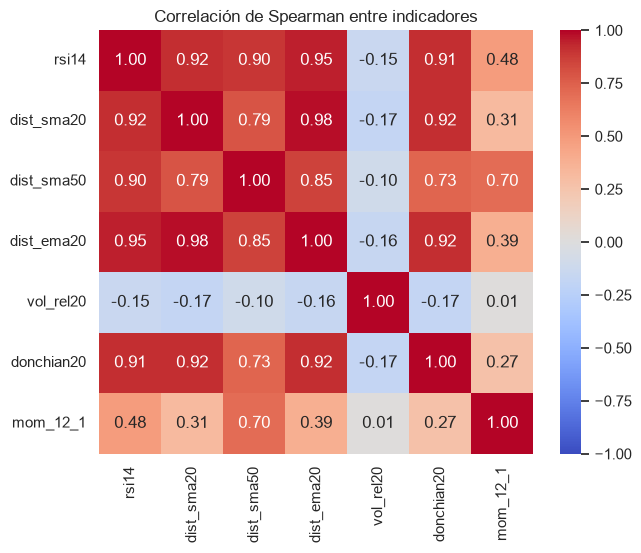

VIF (7 indicadores):
 {'rsi14': 11.24, 'dist_sma20': 35.13, 'dist_sma50': 15.76, 'dist_ema20': 55.56, 'vol_rel20': 1.06, 'donchian20': 6.55, 'mom_12_1': 3.54}
Pares con |ρ| > 0.7:
 dist_sma20  dist_ema20   0.9780
rsi14       dist_ema20   0.9460
dist_sma20  donchian20   0.9200
rsi14       dist_sma20   0.9170
dist_ema20  donchian20   0.9160
rsi14       donchian20   0.9140
            dist_sma50   0.8950
dist_sma50  dist_ema20   0.8540
dist_sma20  dist_sma50   0.7890
dist_sma50  donchian20   0.7330
            mom_12_1     0.7020
dtype: float64


In [15]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
C = D[IND].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7, 5.5)); sns.heatmap(C, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlación de Spearman entre indicadores"); fig.savefig(config.DIR_ASSETS / "nb04_spearman_indicadores.png", dpi=150, bbox_inches="tight"); plt.show()
def tabla_vif(cols):
    Z = sm.add_constant((D[cols] - D[cols].mean()) / D[cols].std())
    return pd.Series([variance_inflation_factor(Z.values, i + 1) for i in range(len(cols))], index=cols)
print("VIF (7 indicadores):\n", tabla_vif(IND).round(2).to_dict())
pares = C.where(np.triu(np.ones(C.shape, bool), 1)).stack().sort_values(key=abs, ascending=False)
print("Pares con |ρ| > 0.7:\n", pares[pares.abs() > .7].round(3))

In [16]:
sel = list(IND); pasos = []
while True:
    v = tabla_vif(sel)
    if v.max() < 10: break
    q = v.idxmax(); pasos.append((q, float(round(v[q], 1)), float(round(C.loc[q, [c for c in sel if c != q]].abs().max(), 3))))
    sel.remove(q)
print("Exclusiones sucesivas (indicador, VIF, |ρ| máx. con los restantes):", pasos)
print("Conservados:", sel, "\nVIF finales:", tabla_vif(sel).round(2).to_dict())
print("AUC de los excluidos vs. conservados:\n", tab_auc.loc[IND, ["AUC", "info_mutua"]].assign(conservado=[c in sel for c in IND]))

Exclusiones sucesivas (indicador, VIF, |ρ| máx. con los restantes): [('dist_ema20', 55.6, 0.978), ('dist_sma50', 11.6, 0.895)]
Conservados: ['rsi14', 'dist_sma20', 'vol_rel20', 'donchian20', 'mom_12_1'] 
VIF finales: {'rsi14': 8.41, 'dist_sma20': 4.32, 'vol_rel20': 1.05, 'donchian20': 5.85, 'mom_12_1': 1.38}
AUC de los excluidos vs. conservados:
               AUC  info_mutua  conservado
indicador                                
rsi14      0.5126      0.0000        True
dist_sma20 0.4986      0.0026        True
dist_sma50 0.4964      0.0041       False
dist_ema20 0.4964      0.0026       False
vol_rel20  0.5137      0.0006        True
donchian20 0.5072      0.0000        True
mom_12_1   0.5130      0.0064        True


**Justificación (exclusiones).** Se excluyen de forma sucesiva los indicadores con VIF ≥ 10 (estandarizados): **`dist_ema20`** (VIF 55.6; ρ = 0.978 con `dist_sma20`, que es casi la misma información: la EMA20 es una media de 20 semanas con otro peso) y **`dist_sma50`** (VIF 11.6 tras la primera exclusión; ρ = 0.895 con RSI14 y 0.789 con `dist_sma20`). Entre `dist_sma20` y `dist_ema20` se conserva la SMA por ser más simple y tener la AUC no inferior (0.4986 vs. 0.4964); `dist_sma50` aporta una AUC (0.4964) y una información mutua (0.0041) que no compensan su colinealidad. Quedan 5 indicadores (`rsi14`, `dist_sma20`, `vol_rel20`, `donchian20`, `mom_12_1`) con VIF máx. 8.4 (RSI) y 5.9 (Donchian). La redundancia es entre las variables de nivel de precio (RSI, distancias y Donchian, con ρ de 0.91–0.95 entre sí); `vol_rel20` (VIF 1.05) y `mom_12_1` (1.38) son prácticamente independientes del resto. Esta selección es para la interpretación y el SVM; la regularización del modelo puede tolerar algo de colinealidad.

**Síntesis (secciones 4–5).**
- HT2: **no concluyente** por la regla de 4.4 (0 de 7 indicadores asociados); ningún indicador excluye 0.5 con el IC por bloques de fechas (`vol_rel20` 0.5137, 0.486–0.542; con bloques por ticker, 0.502–0.527); RSI, momentum y Donchian apuntan en el sentido esperado sin significancia; la información mutua es ≤ 0.0064.
- E2: 5 indicadores conservados (se excluyen `dist_ema20` y `dist_sma50` por VIF y por ρ); alimenta las características del SVM (Tarea de modelado).
- Expectativa para HT1: un modelo con estos rasgos solo mejoraría la línea base por interacciones o por σ; se medirá con AUC/Brier walk-forward.

## 6. HT3: estabilidad por régimen de mercado
Los regímenes se justifican con los drawdowns del SPY (calculados sobre el cierre semanal ajustado).

In [17]:
spy = cl["SPY"].dropna(); dd_spy = spy / spy.cummax() - 1
cortes = dd_spy[dd_spy < -0.15].index
grupos_ep = np.split(cortes, np.where(np.diff(cortes.values).astype("timedelta64[D]") > np.timedelta64(120, "D"))[0] + 1)
for g in grupos_ep:
    valle = dd_spy.loc[g].idxmin(); pico = spy.loc[:valle].idxmax()
    print(f"Pico {pico.date()}  valle {valle.date()}  profundidad {dd_spy[valle]:.1%}")
print("Primer dato SPY:", spy.index[0].date(), "| drawdown inicial:", f"{dd_spy.iloc[0]:.1%}")
print("Máx. drawdown ene–jun 2009:", f"{dd_spy['2009-01':'2009-06'].min():.1%}", "| mar-2009 valle:", dd_spy['2009-01':'2009-06'].idxmin().date())
anual = spy.resample("YE").last().pct_change().dropna(); print("Retorno anual SPY:", (anual * 100).round(1).rename(lambda f: f.year).to_dict())

Pico 2009-01-05  valle 2009-03-02  profundidad -22.6%
Pico 2010-04-19  valle 2010-06-28  profundidad -15.7%
Pico 2011-04-25  valle 2011-08-15  profundidad -17.0%
Pico 2018-09-17  valle 2018-12-17  profundidad -17.1%
Pico 2020-02-10  valle 2020-03-16  profundidad -31.8%
Pico 2021-12-27  valle 2022-09-26  profundidad -23.9%
Pico 2025-02-10  valle 2025-03-31  profundidad -16.9%
Primer dato SPY: 2009-01-05 | drawdown inicial: 0.0%
Máx. drawdown ene–jun 2009: -22.6% | mar-2009 valle: 2009-03-02
Retorno anual SPY: {2010: 15.1, 2011: 1.9, 2012: 19.2, 2013: 27.5, 2014: 14.5, 2015: 1.3, 2016: 12.0, 2017: 21.7, 2018: -3.6, 2019: 30.2, 2020: 18.1, 2021: 28.7, 2022: -18.2, 2023: 26.2, 2024: 26.1, 2025: 16.8, 2026: 14.8}


**Lectura (drawdowns del SPY):** los episodios de caída > 15 % son: valle de marzo de 2009 (−22.6 % desde el primer dato de la muestra, enero de 2009, por lo que subestima la crisis 2007–09 completa), COVID (pico 2020-02-10, valle 2020-03-16, −31.8 %), el mercado bajista de 2022 (pico 2021-12-27, valle 2022-09-26, −23.9 %) y caídas menores (−15.7 % a −17.1 % en 2010, 2011, 2018 y 2025).

**Justificación (regímenes).** Se definen cinco regímenes según la fecha de entrada t: **Crisis 2009** (2009-01-05 a 2009-12-31: valle −22.6 % y rebote posterior; la muestra no incluye 2008); **Expansión** (2010-01-01 a 2020-01-31 y 2020-05-01 a 2021-12-26, con retornos anuales del SPY positivos salvo 2018: −3.6 %); **COVID** (2020-02-01 a 2020-04-30, el pico y valle de −31.8 %); **Bajista 2022** (2021-12-27 a 2022-12-31, −23.9 %); **Reciente** (desde 2023-01-01). Las fechas siguen los picos y valles anteriores, no se eligieron mirando la AUC.

In [18]:
REG = [("Crisis 2009", "2009-01-05", "2009-12-31"), ("Expansión", "2010-01-01", "2020-01-31"),
       ("COVID", "2020-02-01", "2020-04-30"), ("Expansión", "2020-05-01", "2021-12-26"),
       ("Bajista 2022", "2021-12-27", "2022-12-31"), ("Reciente", "2023-01-01", "2026-12-31")]
D2 = panel.dropna(subset=[Y]).reset_index(drop=True); D2["regimen"] = None
for nombre, a, b in REG:
    D2.loc[(D2.fecha >= a) & (D2.fecha <= b), "regimen"] = nombre
orden = ["Crisis 2009", "Expansión", "COVID", "Bajista 2022", "Reciente"]
bal_reg = D2.groupby("regimen")[Y].agg(n="count", pct_clase1="mean").loc[orden]
bal_reg["n_clase1"] = D2.groupby("regimen")[Y].sum().loc[orden].astype(int)
bal_reg["dd_SPY_max"] = [min(dd_spy[(dd_spy.index >= a) & (dd_spy.index <= b)].min() for nom, a, b in REG if nom == r) for r in orden]   # Expansión: solo sus dos segmentos (sin COVID)
print(bal_reg)

                  n  pct_clase1  n_clase1  dd_SPY_max
regimen                                              
Crisis 2009    1428      0.0532        76     -0.2264
Expansión     17948      0.1577      2831     -0.1708
COVID           390      0.3692       144     -0.3183
Bajista 2022   1590      0.3346       532     -0.2393
Reciente       5580      0.1837      1025     -0.1743


**Lectura (balance de clases):** el porcentaje de clase 1 depende fuertemente del régimen: 5.3 % en Crisis 2009 (1 428 filas, 76 positivas), 15.8 % en Expansión (17 948), 36.9 % en COVID (390 filas) y 33.5 % en Bajista 2022 (1 590), contra 18.4 % en Reciente (5 580). La tasa base de la clase 1 se multiplica por más de 2 en los regímenes de caída; un modelo que ignore el régimen heredaría esa variación.

In [19]:
TOP3 = tab_auc.assign(d=(tab_auc.AUC - .5).abs()).sort_values("d", ascending=False).index[:3].tolist()
print("Top 3 por |AUC − 0.5|:", TOP3)
MIN_SEM = 10 * 12   # 10·N semanas (N = 12): mínimo para un IC por régimen
def auc_boot(sub, c, reps=200, sem_=7):
    """Block bootstrap por FECHA: bloques contiguos de semanas comunes a todos los tickers (conserva la dependencia transversal)."""
    r = np.random.default_rng(sem_); fechas = np.sort(sub.fecha.unique()); nd = len(fechas)
    L = 12; pos = {f: g.to_numpy() for f, g in sub.groupby("fecha").groups.items()}
    ys, xs = sub[Y].to_numpy(), sub[c].to_numpy(); a0 = roc_auc_score(ys, xs); bs = np.full(reps, np.nan)
    for b in range(reps):
        ini = r.integers(0, nd - L + 1, int(np.ceil(nd / L)))
        ix = np.concatenate([pos[f] for f in fechas[(ini[:, None] + np.arange(L)).ravel()[:nd]]])
        if 0 < ys[ix].sum() < len(ix): bs[b] = roc_auc_score(ys[ix], xs[ix])
    return a0, np.nanpercentile(bs, 2.5), np.nanpercentile(bs, 97.5), L
filas = []
for rg_ in orden:
    for c in TOP3:
        sub = D2[(D2.regimen == rg_) & D2[c].notna()].reset_index(drop=True)
        if len(sub) < 300: filas.append(dict(regimen=rg_, indicador=c, n=len(sub))); continue
        sem_reg = sub.fecha.nunique()
        if sem_reg < MIN_SEM:   # menos de 10·N semanas: AUC como punto descriptivo, sin IC (04 §4.4)
            filas.append(dict(regimen=rg_, indicador=c, n=len(sub), semanas=sem_reg, AUC=roc_auc_score(sub[Y], sub[c]))); continue
        a0, l, h, L = auc_boot(sub, c)
        filas.append(dict(regimen=rg_, indicador=c, n=len(sub), semanas=sem_reg, AUC=a0, IC_inf=l, IC_sup=h, bloque=L, excluye_05=(l > .5) or (h < .5)))
tab_reg = pd.DataFrame(filas); print(f"Block bootstrap por fecha: 200 réplicas, bloques de 12 semanas; regímenes con < {MIN_SEM} semanas (10·N): AUC descriptiva, sin IC")
print(tab_reg.pivot(index="regimen", columns="indicador", values="AUC").loc[orden])
print(tab_reg.to_string(index=False))

Top 3 por |AUC − 0.5|: ['vol_rel20', 'mom_12_1', 'rsi14']


Block bootstrap por fecha: 200 réplicas, bloques de 12 semanas; regímenes con < 120 semanas (10·N): AUC descriptiva, sin IC
indicador     mom_12_1  rsi14  vol_rel20
regimen                                 
Crisis 2009        NaN 0.9505     0.4779
Expansión       0.5089 0.5189     0.5131
COVID           0.7875 0.7363     0.4641
Bajista 2022    0.6372 0.6505     0.4715
Reciente        0.4966 0.5130     0.5132
     regimen indicador     n  semanas    AUC  IC_inf  IC_sup  bloque excluye_05
 Crisis 2009 vol_rel20   924  33.0000 0.4779     NaN     NaN     NaN        NaN
 Crisis 2009  mom_12_1     0      NaN    NaN     NaN     NaN     NaN        NaN
 Crisis 2009     rsi14  1064  38.0000 0.9505     NaN     NaN     NaN        NaN
   Expansión vol_rel20 17912 612.0000 0.5131  0.4762  0.5437 12.0000      False
   Expansión  mom_12_1 17846 612.0000 0.5089  0.4599  0.5519 12.0000      False
   Expansión     rsi14 17922 612.0000 0.5189  0.4677  0.5662 12.0000      False
       COVID vol_rel20   390 

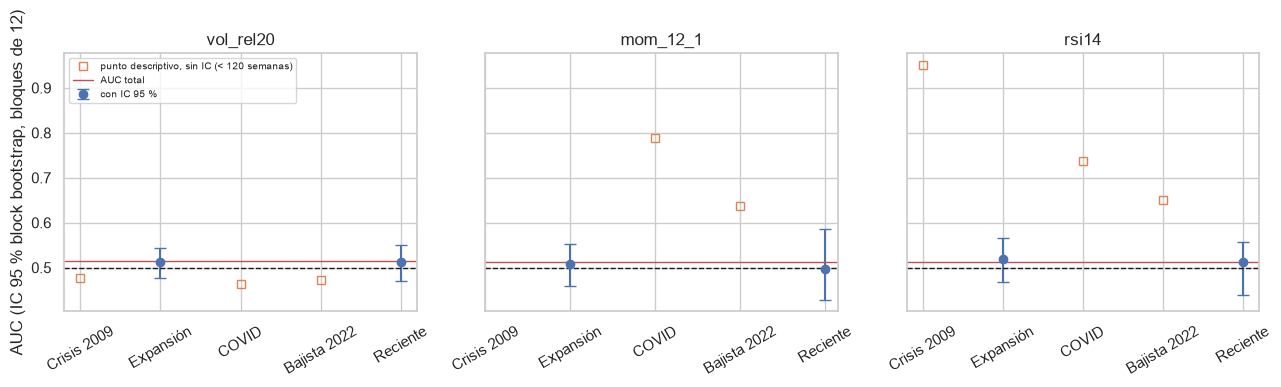

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for a, c in zip(ax, TOP3):
    g = tab_reg[tab_reg.indicador == c].set_index("regimen").loc[orden]
    ci = g.IC_inf.notna().to_numpy(); xs_ = np.arange(len(orden))
    a.errorbar(xs_[ci], g.AUC[ci], yerr=[(g.AUC - g.IC_inf).clip(lower=0)[ci], (g.IC_sup - g.AUC).clip(lower=0)[ci]], fmt="o", capsize=4, label="con IC 95 %")
    a.plot(xs_[~ci], g.AUC[~ci], "s", color="C1", mfc="none", label="punto descriptivo, sin IC (< 120 semanas)")
    a.axhline(.5, color="k", ls="--", lw=1); a.axhline(tab_auc.loc[c, "AUC"], color="C3", lw=1, label="AUC total")
    a.set_xticks(range(len(orden))); a.set_xticklabels([o.replace(" (cola)", "") for o in orden], rotation=30); a.set_title(c)
ax[0].set_ylabel("AUC (IC 95 % block bootstrap, bloques de 12)"); ax[0].legend(fontsize=7, loc="upper left"); fig.tight_layout()
fig.savefig(config.DIR_ASSETS / "nb04_auc_por_regimen.png", dpi=150, bbox_inches="tight"); plt.show()

**Lectura (AUC por régimen):** en Expansión y Reciente (≈ 87 % de las observaciones) las AUC de `vol_rel20`, `mom_12_1` y `rsi14` quedan en 0.497–0.519 con IC que incluyen 0.5, igual que en el total. En COVID (13 semanas) y Bajista 2022 (53 semanas), con menos de 10·N = 120 semanas, no se calcula IC y la AUC es un punto descriptivo: sube la de `mom_12_1` (0.788 y 0.637) y la de `rsi14` (0.736 y 0.651), y `vol_rel20` queda bajo 0.5 (0.464 y 0.472). En Crisis 2009 (33 a 38 semanas con indicador, tampoco IC) el RSI tiene una AUC de 0.951, pero no es discriminación: son 76 positivos (de 1 428 filas) concentrados en pocas fechas comunes, y la AUC mide el timing de un evento, el rebote de principios de 2009 con RSI alto seguido de caídas; además los indicadores necesitan 14 a 52 semanas de arranque (`mom_12_1` no existe en 2009).

**Advertencia sobre los IC por régimen.** Solo Expansión (612 semanas) y Reciente (186) alcanzan 10·N = 120 semanas y tienen IC, con bloques de 12 semanas (iguales a N, como pide 4.4); Crisis 2009, COVID y Bajista 2022 se reportan como puntos descriptivos, sin IC, y la figura los muestra sin barras de error. Cada uno de los tres es además un único evento común a todos los tickers.

**Justificación (HT3).** La señal **no es estable entre regímenes**: es débil e indistinguible de 0.5 en el 87 % de la muestra y sube a 0.64–0.79 en caídas de mercado, donde indicadores como RSI y momentum altos preceden con más frecuencia caídas de al menos 1σ√N. Se interpreta con cautela, como asociación: en COVID y 2022 hay un único evento común a todos los tickers (sin IC por régimen: son puntos descriptivos) y la clase 1 es allí 2 veces más frecuente, de modo que la AUC mezcla la discriminación con el timing del evento. El estado se fija con la regla literal de 4.4 en la celda siguiente (**no apoyada**). Decisión: se registra el régimen o la volatilidad del mercado como rasgo candidato y se evalúa el SVM walk-forward por régimen.

**Síntesis (sección 6).**
- Regímenes definidos con drawdowns del SPY (COVID −31.8 %, 2022 −23.9 %, 2009 −22.6 %); la muestra empieza en 2009.
- Clase 1: 5.3 % (2009), 15.8 % (expansión), 36.9 % (COVID), 33.5 % (2022), 18.4 % (reciente).
- La AUC de RSI y momentum pasa de ≈ 0.51 (expansión y reciente) a 0.64–0.79 (COVID y 2022); la relación no es estable. Alimenta la validación walk-forward por régimen (HT1).

In [21]:
# Regla literal de HT3 (04_enfoque_analitico.md, 4.4), por indicador (los 3 de mayor |AUC − 0.5| de la sección 4)
# Régimen con muestra suficiente: aquel donde se calculó la AUC (>= 300 filas con el indicador; regla de la celda anterior).
# El "signo de la asociación" es el de AUC − 0.5 en la muestra completa; la relación es estable si ese signo se mantiene
# en más de la mitad de los regímenes con muestra suficiente.
# CONVENCIÓN (no escrita en 4.4): la hipótesis se apoya solo si la relación es estable en TODOS los indicadores analizados,
# porque 4.1 enuncia la estabilidad como afirmación universal y así se evita declarar estabilidad de más.
# Los 3 indicadores son los de mayor |AUC − 0.5| en la sección 4 (selección post hoc).
filas = []
for c in TOP3:
    g = tab_reg[(tab_reg.indicador == c) & tab_reg.AUC.notna()].set_index("regimen")
    s_tot = np.sign(tab_auc.loc[c, "AUC"] - .5); coinc = int((np.sign(g.AUC - .5) == s_tot).sum())
    filas.append(dict(indicador=c, AUC_total=tab_auc.loc[c, "AUC"], signo_total="+" if s_tot > 0 else "−",
                      signos_por_regimen=", ".join(f"{r} {'+' if a > .5 else '−'}" for r, a in g.AUC.items()),
                      regimenes=len(g), coinciden=coinc, estable=coinc > len(g) / 2))
ht3_t = pd.DataFrame(filas).set_index("indicador"); print(ht3_t.to_string())
ESTADO_HT3 = "apoyada" if ht3_t.estable.all() else "no apoyada"   # convención: todos los indicadores
ALT_HT3 = "apoyada" if ht3_t.estable.sum() > len(ht3_t) / 2 else "no apoyada"   # lectura alternativa: mayoría de indicadores
con_ic = tab_reg.IC_inf.notna(); n_reg_ev = int(con_ic.sum()); n_sin_ic = int((tab_reg.AUC.notna() & ~con_ic).sum())
ic_con_05 = int((con_ic & ~tab_reg.excluye_05.fillna(False).astype(bool)).sum())
print(f"REGLA HT3: estable si el signo de AUC − 0.5 se mantiene en la mayoría de los regímenes con muestra suficiente -> RESULTADO: "
      + "; ".join(f"{i} {r.coinciden}/{r.regimenes}" for i, r in ht3_t.iterrows())
      + f"; estables: {list(ht3_t.index[ht3_t.estable])} -> ESTADO HT3 (convención: estable en todos): {ESTADO_HT3}")
print(f"Lectura alternativa (mayoría de indicadores): {int(ht3_t.estable.sum())} de {len(ht3_t)} estables -> {ALT_HT3}; "
      f"celdas indicador × régimen con IC (regímenes de >= 120 semanas): {n_reg_ev}; {ic_con_05} incluyen 0.5; {n_sin_ic} celdas más son puntos sin IC")

           AUC_total signo_total                                               signos_por_regimen  regimenes  coinciden  estable
indicador                                                                                                                       
vol_rel20     0.5137           +  Crisis 2009 −, Expansión +, COVID −, Bajista 2022 −, Reciente +          5          2    False
mom_12_1      0.5130           +                 Expansión +, COVID +, Bajista 2022 +, Reciente −          4          3     True
rsi14         0.5126           +  Crisis 2009 +, Expansión +, COVID +, Bajista 2022 +, Reciente +          5          5     True
REGLA HT3: estable si el signo de AUC − 0.5 se mantiene en la mayoría de los regímenes con muestra suficiente -> RESULTADO: vol_rel20 2/5; mom_12_1 3/4; rsi14 5/5; estables: ['mom_12_1', 'rsi14'] -> ESTADO HT3 (convención: estable en todos): no apoyada
Lectura alternativa (mayoría de indicadores): 2 de 3 estables -> apoyada; celdas indicador × régimen c

**Lectura (regla literal de HT3):** la regla de 4.4 pide que el signo de la asociación se mantenga en la mayoría de los regímenes con muestra suficiente (aquí, los regímenes donde se calculó la AUC: al menos 300 filas, criterio distinto de las 120 semanas (10·N) que se exigen solo para calcular el IC; `mom_12_1` no existe en Crisis 2009). Con el signo de la muestra completa (AUC > 0.5 en los tres), `rsi14` lo mantiene en 5 de 5 regímenes y `mom_12_1` en 3 de 4 (Reciente 0.4966, prácticamente 0.5), así que ambos son estables en signo; `vol_rel20` solo en 2 de 5 (Expansión 0.5131 y Reciente 0.5132; Crisis 2009, COVID y Bajista 2022 por debajo de 0.5), así que no lo es. 4.4 no dice cómo combinar los indicadores; se usa la **convención** de exigir estabilidad en todos los indicadores analizados, porque 4.1 enuncia la estabilidad como afirmación universal y es la opción conservadora frente a declarar estabilidad. **Estado según la regla y la convención: HT3 no apoyada.**

**Desviación documentada (no cambia el estado).** *Lectura alternativa:* con la mayoría de indicadores en lugar de todos, 2 de 3 son estables y HT3 se leería como apoyada. *Selección post hoc:* los 3 indicadores son los de mayor |AUC − 0.5| en la sección 4, elegidos después de ver los datos. *Signos puntuales:* los signos por régimen son estimaciones puntuales; de las 14 celdas indicador × régimen solo 6 (Expansión y Reciente) tienen IC y las 6 incluyen 0.5; las otras 8 son puntos descriptivos sin IC (menos de 10·N = 120 semanas). *Magnitud:* aun donde el signo se mantiene (RSI y momentum), la AUC pasa de ≈ 0.51 en Expansión y Reciente a 0.64–0.79 en COVID y Bajista 2022, lo que refuerza evaluar el SVM por régimen.

## 7. HP3: modelo de índice único frente al ETF sectorial
**HP3.** El ETF sectorial explica una parte importante del movimiento de cada acción, de modo que la probabilidad de alcanzar un objetivo depende en buena medida del sector. Se estima, por ticker, r_i = α + β·r_ETF + ε con retornos logarítmicos semanales del snapshot ajustado (`precios_semanales`). El R² es la fracción sistemática de la varianza y 1 − R² la idiosincrática. Los resultados son asociativos y los retornos semanales presentan dependencia de volatilidad (HP0), por lo que los errores estándar clásicos no se usan.

In [22]:
RET = np.log(cl).diff().iloc[1:]
filas = {}
for t in config.tickers():
    ind_t = config.industria_de(t); etf = config.ETF_SECTOR[ind_t]
    b = rg.beta_alpha(RET[t], RET[etf])
    filas[t] = dict(industria=ind_t, etf=etf, n=int(RET[[t, etf]].dropna().shape[0]), beta=b["beta"],
                    alpha_anual=b["alpha"] * config.PERIODOS_ANIO, r2=b["r2"], sigma_idio_anual=b["sigma_idio"] * np.sqrt(config.PERIODOS_ANIO))
hp3 = pd.DataFrame(filas).T
for c in ["beta", "alpha_anual", "r2", "sigma_idio_anual"]: hp3[c] = hp3[c].astype(float)
hp3["pct_idiosincratico"] = 1 - hp3.r2
print(hp3.drop(columns=["etf"]).round(3).to_string())
res_hp3 = hp3.groupby("industria").agg(r2_mediana=("r2", "median"), r2_min=("r2", "min"), r2_max=("r2", "max"), beta_mediana=("beta", "median"))
print(res_hp3.round(3)); print("R² mediano global:", round(hp3.r2.median(), 3), "| tickers con R² > 0.5:", int((hp3.r2 > .5).sum()), "de", len(hp3))
print("Mayor R²:", hp3.r2.idxmax(), round(hp3.r2.max(), 3), "| menor R²:", hp3.r2.idxmin(), round(hp3.r2.min(), 3))

               industria    n   beta  alpha_anual     r2  sigma_idio_anual  pct_idiosincratico
AAPL          tecnologia  927 1.0110       0.0750 0.5270            0.1940              0.4730
MSFT          tecnologia  927 0.9020       0.0290 0.5510            0.1650              0.4490
GOOGL         tecnologia  927 0.9020       0.0390 0.4440            0.2040              0.5560
META          tecnologia  752 0.9450       0.0220 0.2500            0.3300              0.7500
NVDA          tecnologia  927 1.5190       0.1050 0.5010            0.3070              0.4990
ORCL          tecnologia  927 0.9130      -0.0460 0.3790            0.2360              0.6210
ADBE          tecnologia  927 0.9690      -0.0600 0.3950            0.2420              0.6050
CRM           tecnologia  927 1.0700      -0.0160 0.3760            0.2790              0.6240
CSCO          tecnologia  927 0.7750      -0.0170 0.3700            0.2050              0.6300
INTC          tecnologia  927 1.0590      -0.0680 

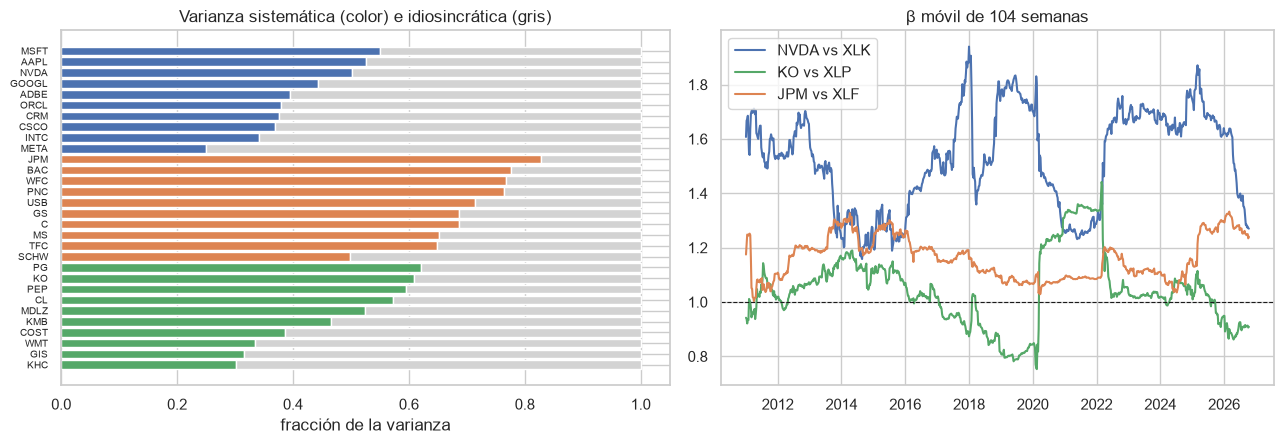

NVDA: β móvil mín 1.16 (2014-08-25), máx 1.94 (2018-01-01), último 1.27, β completo 1.52
KO: β móvil mín 0.75 (2020-02-17), máx 1.44 (2022-02-28), último 0.91, β completo 1.06
JPM: β móvil mín 1.00 (2011-04-04), máx 1.33 (2026-03-02), último 1.24, β completo 1.15


In [23]:
TRES = {"tecnologia": "NVDA", "consumo_defensivo": "KO", "financiero": "JPM"}
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.1, 1]})
orden = hp3.sort_values(["industria", "r2"]); cols = {"tecnologia": "C0", "consumo_defensivo": "C2", "financiero": "C1"}
ax[0].barh(orden.index, orden.r2, color=[cols[i] for i in orden.industria]); ax[0].barh(orden.index, orden.pct_idiosincratico, left=orden.r2, color="lightgray")
ax[0].set_title("Varianza sistemática (color) e idiosincrática (gris)"); ax[0].set_xlabel("fracción de la varianza"); ax[0].tick_params(axis="y", labelsize=7)
roll = {}
for ramo, t in TRES.items():
    etf = config.ETF_SECTOR[ramo]; d = RET[[t, etf]].dropna()
    cov = d[t].rolling(104).cov(d[etf]); roll[t] = cov / d[etf].rolling(104).var()
    ax[1].plot(roll[t], label=f"{t} vs {etf}", c=cols[ramo])
ax[1].axhline(1, c="k", ls="--", lw=.8); ax[1].set_title("β móvil de 104 semanas"); ax[1].legend()
fig.tight_layout(); fig.savefig(config.DIR_ASSETS / "nb04_hp3_indice_unico.png", dpi=150, bbox_inches="tight"); plt.show()
for t, s in roll.items():
    s = s.dropna(); print(f"{t}: β móvil mín {s.min():.2f} ({s.idxmin().date()}), máx {s.max():.2f} ({s.idxmax().date()}), último {s.iloc[-1]:.2f}, β completo {hp3.loc[t,'beta']:.2f}")

**Lectura:** el R² mediano es 0.525 en el conjunto (17 de 30 tickers superan 0.5) y cambia con la industria: 0.700 en financieras (0.499 a 0.828, máximo JPM), 0.495 en consumo defensivo (0.302 a 0.621) y 0.387 en tecnología (0.250 a 0.551, mínimo META). Es decir, en financieras cerca de 70 % de la varianza semanal es sistemática (asociada al ETF) y en tecnología menos de 40 %. El β móvil de 104 semanas no es constante: NVDA va de 1.16 a 1.94 (β completo 1.52), KO de 0.75 a 1.44 y JPM de 1.00 a 1.33; un único β histórico oculta ese rango, por lo que la simulación debe leerse como condicional a la muestra.

In [24]:
# IC 95 % de β por ticker (bootstrap por bloques de 12 fechas) y R² del índice único por régimen (regímenes de la sección 6)
import time
from asistente.validacion import ic_bootstrap_fechas
t0 = time.time()
def pendiente_mco(d):
    """β de MCO: cov(r_activo, r_etf) / var(r_etf)."""
    return np.cov(d.r_activo, d.r_etf, ddof=1)[0, 1] / d.r_etf.var(ddof=1)
filas = {}
for t in config.tickers():
    etf = config.ETF_SECTOR[config.industria_de(t)]
    d = RET[[t, etf]].dropna().rename(columns={t: "r_activo", etf: "r_etf"}).rename_axis("fecha").reset_index()
    b, lo_, hi_ = ic_bootstrap_fechas(d, pendiente_mco, bloque=12, reps=300, semilla=42)
    filas[t] = dict(industria=config.industria_de(t), beta=b, IC_inf=lo_, IC_sup=hi_, excluye_0=(lo_ > 0) or (hi_ < 0))
ic_beta = pd.DataFrame(filas).T
for c in ["beta", "IC_inf", "IC_sup"]: ic_beta[c] = ic_beta[c].astype(float)
print("IC 95 % de β por ticker: bootstrap por bloques de 12 fechas, 300 réplicas")
print(ic_beta.round(3).to_string())
print("\nTickers cuyo IC de β excluye 0, por industria:\n",
      ic_beta.groupby("industria").agg(n=("beta", "size"), excluyen_0=("excluye_0", "sum"), IC_inf_min=("IC_inf", "min"), IC_sup_max=("IC_sup", "max")).round(3).to_string())
# R² por régimen: mismas fechas de la sección 6 (Expansión une sus dos tramos); la fecha es la del retorno semanal
ORDEN_REG = ["Crisis 2009", "Expansión", "COVID", "Bajista 2022", "Reciente"]; MIN_SEM = 26
reg_fecha = pd.Series(None, index=RET.index, dtype=object)
for nombre, a, b in REG: reg_fecha[(RET.index >= a) & (RET.index <= b)] = nombre
filas = []
for t in config.tickers():
    etf = config.ETF_SECTOR[config.industria_de(t)]
    for rg_ in ORDEN_REG:
        d = RET.loc[reg_fecha == rg_, [t, etf]].dropna()
        filas.append(dict(ticker=t, industria=config.industria_de(t), regimen=rg_, semanas=len(d),
                          r2=rg.beta_alpha(d[t], d[etf])["r2"] if len(d) >= MIN_SEM else np.nan))
r2_reg = pd.DataFrame(filas)
print("\nSemanas por régimen (máximo por ticker):", r2_reg.groupby("regimen").semanas.max().loc[ORDEN_REG].to_dict())
print(f"Celdas omitidas (< {MIN_SEM} semanas):", r2_reg[r2_reg.r2.isna()].groupby("regimen").ticker.apply(lambda s: ", ".join(s) if len(s) < 10 else f"{len(s)} tickers").to_dict())
tab_r2_reg = r2_reg.pivot_table(index="industria", columns="regimen", values="r2", aggfunc="median").reindex(columns=ORDEN_REG)
print("\nR² mediano por industria y régimen (modelo de índice único dentro de cada régimen):\n", tab_r2_reg.round(3).to_string())
print("Industrias × régimen con R² mediano ≥ 0.30:", int((tab_r2_reg >= .30).sum().sum()), "de", int(tab_r2_reg.notna().sum().sum()))
print(f"Tiempo de la celda: {time.time() - t0:.0f} s")

IC 95 % de β por ticker: bootstrap por bloques de 12 fechas, 300 réplicas
               industria   beta  IC_inf  IC_sup excluye_0
AAPL          tecnologia 1.0110  0.9130  1.0860      True
MSFT          tecnologia 0.9020  0.8490  0.9620      True
GOOGL         tecnologia 0.9020  0.8420  0.9890      True
META          tecnologia 0.9450  0.8540  1.0600      True
NVDA          tecnologia 1.5190  1.3930  1.6450      True
ORCL          tecnologia 0.9130  0.8140  1.0230      True
ADBE          tecnologia 0.9690  0.8330  1.1150      True
CRM           tecnologia 1.0700  0.9430  1.2300      True
CSCO          tecnologia 0.7750  0.6880  0.8590      True
INTC          tecnologia 1.0590  0.9130  1.1690      True
KO     consumo_defensivo 1.0570  0.9490  1.1680      True
PEP    consumo_defensivo 0.9980  0.9120  1.0910      True
PG     consumo_defensivo 0.9910  0.9400  1.0470      True
WMT    consumo_defensivo 0.8730  0.7370  1.0140      True
COST   consumo_defensivo 0.9620  0.8400  1.0960      Tru

**Lectura (IC de β y R² por régimen):** con bootstrap por bloques de 12 fechas (300 réplicas), el IC 95 % de β excluye 0 en los 30 tickers (10 de 10 en cada industria); el límite inferior más bajo es 0.688 (CSCO, tecnología) y 0.695 (GIS, consumo defensivo). En esta sección el régimen se asigna por la fecha del retorno semanal (en la sección 6, por la fecha de entrada t de la ventana). Por régimen, el R² mediano de financieras se mantiene entre 0.629 (Reciente) y 0.738 (Bajista 2022); consumo defensivo va de 0.362 (Reciente) a 0.666 (Bajista 2022), y tecnología de 0.283 (Reciente) a 0.637 (Bajista 2022). Frente a Expansión, el R² mediano es mayor en Bajista 2022 en las tres industrias (consumo defensivo 0.457 → 0.666, financieras 0.731 → 0.738, tecnología 0.412 → 0.637). En Crisis 2009 solo es mayor en tecnología (0.412 → 0.615); en consumo defensivo baja (0.457 → 0.378) y en financieras queda casi igual (0.731 → 0.728). Es decir, la parte de la varianza asociada al ETF tiende a ser mayor en la caída de 2022, sin que eso se repita en todas las industrias en 2009. De las 12 celdas industria × régimen evaluables, 11 tienen R² mediano ≥ 0.30; la excepción es tecnología en Reciente (0.283). COVID (13 semanas) se omite en los 30 tickers y Crisis 2009 en META y KHC, que tienen menos de 26 semanas en el régimen.

In [25]:
# Regla literal de HP3 (04_enfoque_analitico.md, 4.4): se apoya si el IC de β excluye 0 y el R² mediano de cada industria es >= 0.30
# Se aplica con la muestra completa (β e IC de la celda anterior, R² de la sección 7); el R² por régimen se reporta como matiz.
reg_hp3 = ic_beta.groupby("industria").agg(n=("beta", "size"), IC_beta_excluye_0=("excluye_0", "sum")).join(res_hp3[["r2_mediana"]])
reg_hp3["beta_ok"] = reg_hp3.IC_beta_excluye_0 == reg_hp3.n; reg_hp3["r2_ok"] = reg_hp3.r2_mediana >= .30
reg_hp3["cumple"] = reg_hp3.beta_ok & reg_hp3.r2_ok; print(reg_hp3.round(3).to_string())
ESTADO_HP3 = "apoyada" if reg_hp3.cumple.all() else "no apoyada"
print(f"REGLA HP3: IC de β excluye 0 y R² mediano >= 0.30 en cada industria -> RESULTADO: IC de β excluye 0 en {int(ic_beta.excluye_0.sum())} de {len(ic_beta)}; "
      f"R² mediano " + ", ".join(f"{i} {r:.3f}" for i, r in reg_hp3.r2_mediana.items()) + f" -> ESTADO HP3: {ESTADO_HP3}")
print("Matiz por régimen (no cambia el estado): celdas industria × régimen con R² mediano < 0.30:",
      {f"{i} / {r}": round(v, 3) for (i, r), v in tab_r2_reg.stack().items() if v < .30})

                    n IC_beta_excluye_0  r2_mediana  beta_ok  r2_ok  cumple
industria                                                                  
consumo_defensivo  10                10      0.4950     True   True    True
financiero         10                10      0.7000     True   True    True
tecnologia         10                10      0.3870     True   True    True
REGLA HP3: IC de β excluye 0 y R² mediano >= 0.30 en cada industria -> RESULTADO: IC de β excluye 0 en 30 de 30; R² mediano consumo_defensivo 0.495, financiero 0.700, tecnologia 0.387 -> ESTADO HP3: apoyada
Matiz por régimen (no cambia el estado): celdas industria × régimen con R² mediano < 0.30: {'tecnologia / Reciente': 0.283}


**Lectura (regla literal de HP3):** el IC 95 % de β excluye 0 en los 30 tickers (10 de 10 por industria) y el R² mediano de la muestra completa es 0.495 en consumo defensivo, 0.700 en financieras y 0.387 en tecnología, todos ≥ 0.30. **Estado según la regla: HP3 apoyada.** Matiz (no cambia el estado): por régimen, tecnología en Reciente queda en 0.283, por debajo de 0.30; las otras 11 celdas evaluables cumplen.

In [26]:
filas = []
for ramo, t in TRES.items():
    etf = config.ETF_SECTOR[ramo]
    con = sim.simular_indice_unico(RET[t], RET[etf], 52, n_sims=10000, semilla=42, con_sector=True)
    sin = sim.simular_indice_unico(RET[t], RET[etf], 52, n_sims=10000, semilla=42, con_sector=False)
    filas.append(dict(ticker=t, etf=etf, r2=hp3.loc[t, "r2"], p20_con_sector=sim.prob_alcanzar(con, 1.20), p20_sin_sector=sim.prob_alcanzar(sin, 1.20),
                      sd_ret52_con=np.log(con[:, -1]).std(), sd_ret52_sin=np.log(sin[:, -1]).std()))
simtab = pd.DataFrame(filas).set_index("ticker"); simtab["diferencia_pp"] = (simtab.p20_con_sector - simtab.p20_sin_sector) * 100
print(simtab.round(3).to_string())

        etf     r2  p20_con_sector  p20_sin_sector  sd_ret52_con  sd_ret52_sin  diferencia_pp
ticker                                                                                       
NVDA    XLK 0.5010          0.8590          0.8690        0.4270        0.3020        -1.0400
KO      XLP 0.6090          0.4760          0.3270        0.1770        0.1110        14.9200
JPM     XLF 0.8280          0.6700          0.5360        0.3080        0.1280        13.4500


**Lectura (con y sin sector):** la simulación con índice único (10 000 trayectorias por bootstrap de pares de residuos y retornos del ETF, 52 semanas, semilla fija) da P(alcanzar +20 %) de 0.476 con sector y 0.327 sin sector en KO (+14.9 pp), 0.670 y 0.536 en JPM (+13.5 pp) y 0.859 y 0.869 en NVDA (−1.0 pp). En "sin sector" el retorno del ETF se fija en su media y solo varía el residuo; por eso la comparación mide cuánto cambia la probabilidad de tocar el nivel al permitir que el sector fluctúe, no es una descomposición aditiva del aporte del sector. La desviación del retorno a 52 semanas pasa de 0.111 a 0.177 en KO y de 0.128 a 0.308 en JPM. En NVDA el α histórico (≈ 10 % anual) domina y la probabilidad es alta con o sin sector, un resultado condicionado a una muestra de éxito extremo (sesgo de supervivencia).

**Justificación (HP3).** Se usa el ETF sectorial como único factor (modelo de índice único) y no SPY porque la hipótesis pregunta por el sector y porque el ETF es el comparador natural en la etiqueta relativa. El β móvil de 104 semanas (2 años) equilibra estabilidad y capacidad de reflejar cambios. La comparación con/sin sector evita afirmar causalidad y no suma contribuciones.

**Síntesis (HP3).**
- **HP3 apoyada** por la regla de 4.4 (IC de β excluye 0 en 30 de 30 y R² mediano ≥ 0.30 en las tres industrias): el sector explica una parte importante (R² mediano 0.525), grande en financieras (0.700), moderada en consumo defensivo (0.495) y menor en tecnología (0.387). Matiz: tecnología en Reciente queda en 0.283.
- La dependencia del sector varía en el tiempo (β móvil con rangos amplios) y el α histórico de ganadoras como NVDA infla las probabilidades de alcanzar +20 %.
- **Decisión que alimenta:** el motor probabilístico debe condicionar al sector donde el R² es alto (financieras) y reportar la parte idiosincrática en tecnología; el nivel de salida se acompaña de una advertencia de β inestable.

## 8. HF2: múltiplo relativo a la industria
**HF2.** El múltiplo relativo (empresa ÷ mediana de su industria en la misma fecha) revierte, de modo que los descuentos frente al sector tienden a cerrarse. Se usa P/E para tecnología y consumo defensivo y P/B para las financieras (el P/E de un banco mezcla apalancamiento y provisiones). Para evitar el sesgo de splits se usa, como en el notebook 03, EPS y valor en libros ajustados por splits (`ajustar_por_splits`) y el cierre de `precios_semanales_sd` (ajustado por splits, no por dividendos). GOOGL se excluye porque EDGAR no trae acciones y su P/E casi no existe.

In [27]:
from statsmodels.tsa.stattools import adfuller
rat = datos.cargar_snapshot("ratios_anuales"); splits = datos.cargar_snapshot("splits")
ancho_sd = datos.a_ancho(datos.cargar_snapshot("precios_semanales_sd"))
mult = {}
for t in config.tickers():
    col = "pb" if t in config.UNIVERSO["financiero"] else "pe"
    pr = ancho_sd[t].dropna().rename("close").rename_axis("fecha").reset_index()
    m = fu.multiplos_semanales(pr, fu.ajustar_por_splits(rat[rat.ticker == t], splits[splits.ticker == t])).set_index("fecha")
    mult[t] = m[col]
MULT = pd.DataFrame(mult).drop(columns="GOOGL")
REL, PCTG = {}, {}
for ramo, lista in config.UNIVERSO.items():
    w = MULT[[t for t in lista if t in MULT.columns]]
    REL[ramo] = fu.multiplo_relativo(w); PCTG[ramo] = fu.percentil_en_grupo(w)
REL = pd.concat(REL.values(), axis=1)[MULT.columns]; PCTG = pd.concat(PCTG.values(), axis=1)[MULT.columns]
print("Cobertura no-NaN del múltiplo (mediana):", round(MULT.notna().mean().median(), 3), "| fechas", MULT.index.min().date(), "a", MULT.index.max().date())
filas = {}
for t in REL:
    x = REL[t].dropna()
    if len(x) < 150: filas[t] = {"n": len(x)}; continue
    ou = rg.ajuste_ou(x)
    filas[t] = {"n": len(x), "ADF_p": adfuller(x)[1], "m": ou["m"], "eta": ou["eta"], "vida_media_anios": ou["vida_media_anios"],
                "sigma": ou["sigma"], "rel_actual": x.iloc[-1], "pct_industria_actual": PCTG[t].dropna().iloc[-1]}
hf2 = pd.DataFrame(filas).T.astype(float); hf2["industria"] = [config.industria_de(t) for t in hf2.index]
hf2["revierte"] = hf2.eta.notna() & (hf2.ADF_p < .05)
print(hf2.round(3).to_string())

Cobertura no-NaN del múltiplo (mediana): 0.916 | fechas 2009-01-05 a 2026-10-12


            n  ADF_p       m    eta  vida_media_anios   sigma  rel_actual  pct_industria_actual          industria  revierte
AAPL 885.0000 0.1140  0.9430 1.5850            0.4370  0.4420      1.4520                0.8750         tecnologia     False
MSFT 846.0000 0.0370  1.1170 1.3280            0.5220  0.5180      0.9620                0.3750         tecnologia      True
META 715.0000 0.0150  5.5730 1.5810            0.4380 44.3030      1.0310                0.6250         tecnologia      True
NVDA 761.0000 0.0240  2.1350 1.9000            0.3650  3.0100      1.4820                1.0000         tecnologia      True
ORCL 850.0000 0.0970  0.9400 1.0690            0.6480  0.4470      0.7760                0.2500         tecnologia     False
ADBE 873.0000 0.3480  2.1800 0.4330            1.6020  1.8680      0.4490                0.1250         tecnologia     False
CRM  553.0000 0.0520 11.4180 1.5420            0.4490 22.1980      0.9690                0.5000         tecnologia     False


In [28]:
v = hf2.dropna(subset=["ADF_p"]); rev = v[v.revierte]
print("Evaluables:", len(v), "| ADF p<0.05:", int((v.ADF_p < .05).sum()), "| eta finito:", int(v.eta.notna().sum()), "| revierten (ambos):", len(rev))
print("Vida media (años) entre los que revierten: mediana", round(rev.vida_media_anios.median(), 2), "rango", round(rev.vida_media_anios.min(), 2), "-", round(rev.vida_media_anios.max(), 2))
print("Vida media mediana todos con eta finito:", round(v.vida_media_anios.median(), 2), "| sin reversión (eta NaN):", list(v.index[v.eta.isna()]))
print("Revierten por industria:", {i: f"{int(g.revierte.sum())}/{len(g)}" for i, g in v.groupby("industria")})
print("Descuento > 20% hoy (rel < 0.8):", {t: round(r, 2) for t, r in v.rel_actual[v.rel_actual < .8].items()})
print("De ellos, con reversión:", [t for t in v.index[v.rel_actual < .8] if v.revierte[t]])

Evaluables: 29 | ADF p<0.05: 10 | eta finito: 28 | revierten (ambos): 10
Vida media (años) entre los que revierten: mediana 0.43 rango 0.21 - 0.67
Vida media mediana todos con eta finito: 0.71 | sin reversión (eta NaN): ['INTC']
Revierten por industria: {'consumo_defensivo': '5/10', 'financiero': '2/10', 'tecnologia': '3/9'}
Descuento > 20% hoy (rel < 0.8): {'ORCL': 0.78, 'ADBE': 0.45, 'PEP': 0.68, 'PG': 0.74, 'KMB': 0.52, 'GIS': 0.31, 'KHC': 0.4, 'C': 0.76, 'TFC': 0.64}
De ellos, con reversión: ['PEP', 'PG', 'C']


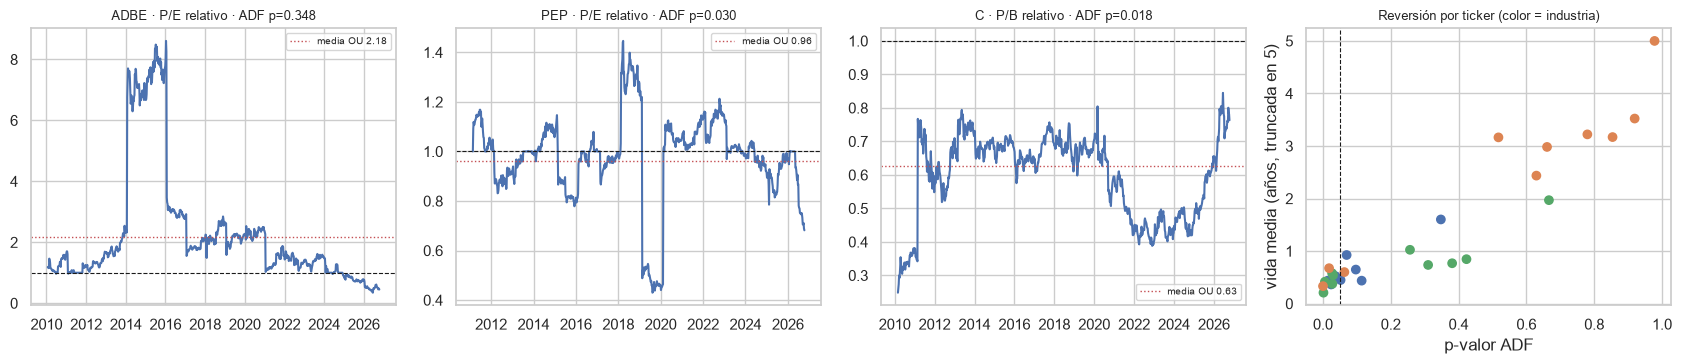

Vida media > 5 años (truncadas en la figura): {'MS': 64.7}
ADBE relativo actual 0.45 | media OU 2.18 | vida media 1.6 | ADF p 0.348
PEP relativo actual 0.68 | media OU 0.96 | vida media 0.54 | ADF p 0.03
C relativo actual 0.76 | media OU 0.63 | vida media 0.67 | ADF p 0.018


In [29]:
REP2 = {"ADBE": "tecnologia", "PEP": "consumo_defensivo", "C": "financiero"}
fig, ax = plt.subplots(1, 4, figsize=(17, 3.8))
for a, t in zip(ax[:3], REP2):
    a.plot(REL[t]); a.axhline(1, c="k", ls="--", lw=.8); a.axhline(hf2.loc[t, "m"], c="C3", ls=":", lw=1, label=f"media OU {hf2.loc[t,'m']:.2f}")
    a.set_title(f"{t} · {'P/B' if t=='C' else 'P/E'} relativo · ADF p={hf2.loc[t,'ADF_p']:.3f}", fontsize=9); a.legend(fontsize=7)
vm = v.dropna(subset=["vida_media_anios"]).copy(); vm["vida_plot"] = vm.vida_media_anios.clip(upper=5)
ax[3].scatter(vm.ADF_p, vm.vida_plot, c=[cols[i] for i in vm.industria]); ax[3].axvline(.05, c="k", ls="--", lw=.8)
ax[3].set_xlabel("p-valor ADF"); ax[3].set_ylabel("vida media (años, truncada en 5)"); ax[3].set_title("Reversión por ticker (color = industria)", fontsize=9)
fig.tight_layout(); fig.savefig(config.DIR_ASSETS / "nb04_hf2_multiplo_relativo.png", dpi=150, bbox_inches="tight"); plt.show()
print("Vida media > 5 años (truncadas en la figura):", {t: round(x, 1) for t, x in vm.vida_media_anios[vm.vida_media_anios > 5].items()})
for t in REP2: print(t, "relativo actual", round(hf2.loc[t, "rel_actual"], 2), "| media OU", round(hf2.loc[t, "m"], 2), "| vida media", round(hf2.loc[t, "vida_media_anios"], 2), "| ADF p", round(hf2.loc[t, "ADF_p"], 3))

**Lectura:** de 29 tickers evaluables, el ADF rechaza la raíz unitaria del múltiplo relativo en 10 (p < 0.05), el ajuste OU da η finito en 28 (INTC no muestra reversión: b fuera de (−2, 0)) y 10 cumplen ambas condiciones: 5 de 10 en consumo defensivo, 3 de 9 en tecnología y 2 de 10 en financieras. Entre esos 10 la vida media es de 0.43 años mediana (rango 0.21 a 0.67); con η finito en los 28 la mediana es 0.71 años, e incluye casos como MS (64.7 años), que en la práctica no revierten. En los tres ejemplos graficados (ADBE, PEP y C), PEP (0.68 hoy, vida media 0.54 años, ADF p = 0.030) sí revierte hacia una media OU de 0.96, mientras ADBE (0.45 hoy, p = 0.348) no pasa la prueba. C (0.76) revierte con p = 0.018, pero su media OU es 0.63, por debajo del nivel actual: su "descuento" frente a los pares es un nivel histórico normal para ese banco, no una anomalía. De los 9 tickers con descuento mayor a 20 % hoy (relativo < 0.8), solo PEP, PG y C pasan la prueba de reversión.

In [30]:
# Regla literal de HF2 (04_enfoque_analitico.md, 4.4), igual que HF1 (nb03 §8) sobre el múltiplo relativo
# Revierte si ADF p < 0.05 Y η > 0 finito Y vida media < mitad de la historia disponible (años entre la primera y la última observación).
# Apoyada si revierten más de la mitad de las empresas evaluables de cada industria. GOOGL excluida (sin P/E).
h2 = hf2.dropna(subset=["ADF_p"]).copy()
h2["hist_anios"] = [(REL[t].dropna().index[-1] - REL[t].dropna().index[0]).days / 365.25 for t in h2.index]
h2["ADF_ok"] = h2.ADF_p < .05; h2["eta_ok"] = h2.eta.notna() & (h2.eta > 0); h2["vida_ok"] = h2.vida_media_anios < h2.hist_anios / 2
h2["pasa"] = h2.ADF_ok & h2.eta_ok & h2.vida_ok
tab_hf2 = []
for ind_, l in config.UNIVERSO.items():
    s_ = h2.loc[h2.index.isin(l)]; k = int(s_.pasa.sum())
    tab_hf2.append({"industria": ind_, "evaluables": len(s_), "ADF ok": int(s_.ADF_ok.sum()), "eta>0": int(s_.eta_ok.sum()), "vida<mitad hist.": int(s_.vida_ok.sum()),
                    "pasan los 3": k, "regla: pasan > n/2": k > len(s_) / 2, "estado": "apoyada" if k > len(s_) / 2 else "no apoyada"})
tab_hf2 = pd.DataFrame(tab_hf2).set_index("industria"); print(tab_hf2.to_string())
print("Historia del múltiplo relativo (años): mediana", round(h2.hist_anios.median(), 1), "rango", round(h2.hist_anios.min(), 1), "-", round(h2.hist_anios.max(), 1))
print("ADF y eta>0 pero vida media >= mitad de la historia:", list(h2.index[h2.ADF_ok & h2.eta_ok & ~h2.vida_ok]))
ESTADO_HF2 = "apoyada" if bool((tab_hf2["estado"] == "apoyada").all()) else "no apoyada"
print(f"REGLA HF2: revierte si ADF<0.05, eta>0 y vida media < mitad de la historia; apoyada si pasan más de la mitad en cada industria -> RESULTADO: "
      f"{int(h2.pasa.sum())} de {len(h2)} pasan (GOOGL excluida); industrias apoyadas: {list(tab_hf2.index[tab_hf2.estado == 'apoyada'])} -> ESTADO HF2: {ESTADO_HF2}")

                   evaluables  ADF ok  eta>0  vida<mitad hist.  pasan los 3  regla: pasan > n/2      estado
industria                                                                                                  
tecnologia                  9       3      8                 8            3               False  no apoyada
consumo_defensivo          10       5     10                10            5               False  no apoyada
financiero                 10       2     10                 9            2               False  no apoyada
Historia del múltiplo relativo (años): mediana 16.5 rango 9.0 - 16.9
ADF y eta>0 pero vida media >= mitad de la historia: []
REGLA HF2: revierte si ADF<0.05, eta>0 y vida media < mitad de la historia; apoyada si pasan más de la mitad en cada industria -> RESULTADO: 10 de 29 pasan (GOOGL excluida); industrias apoyadas: [] -> ESTADO HF2: no apoyada


**Lectura (regla literal de HF2):** como en HF1 (nb03 §8), la regla de 4.4 pide por empresa ADF con p < 0.05, η > 0 finito y vida media menor que la mitad de la historia del múltiplo relativo (9.0 a 16.9 años, mediana 16.5). La vida media no excluye a nadie (los que pasan ADF tienen vidas de 0.21 a 0.67 años), así que deciden ADF y η: pasan 3 de 9 en tecnología, 5 de 10 en consumo defensivo y 2 de 10 en financieras (10 de 29; GOOGL excluida). Ninguna industria supera la mitad: consumo defensivo llega justo a la mitad (5 de 10), que no es más de la mitad. **Estado según la regla: HF2 no apoyada.** Matiz: con series de múltiplos tan autocorrelacionadas la potencia de ADF es baja (4.4).

In [31]:
dpe = datos.cargar_snapshot("damodaran_pe"); ult = MULT.loc[MULT.index >= MULT.index.max() - pd.Timedelta(weeks=52)]
fil = []
for ramo, lista in config.UNIVERSO.items():
    pares = [t for t in lista if t in ult.columns]; med = ult[pares].median().median()
    fe = dm.filas_industria(dpe, ramo)
    fil.append(dict(industria=ramo, multiplo="P/B" if ramo == "financiero" else "P/E", mediana_pares_ult52s=med,
                    damodaran_trailing_pe=np.nan if ramo == "financiero" else fe.trailing_pe.median(),
                    damodaran_current_pe=np.nan if ramo == "financiero" else fe.current_pe.median()))
cmp_dam = pd.DataFrame(fil).set_index("industria"); cmp_dam["razon_vs_trailing"] = cmp_dam.mediana_pares_ult52s / cmp_dam.damodaran_trailing_pe
print(cmp_dam.round(2).to_string()); print("Nota: la tabla pedata de Damodaran trae P/E, no P/B; no hay referencia para las financieras.")

                  multiplo  mediana_pares_ult52s  damodaran_trailing_pe  damodaran_current_pe  razon_vs_trailing
industria                                                                                                       
tecnologia             P/E               32.9100                81.1300              122.4900             0.4100
consumo_defensivo      P/E               25.7500                47.7600               37.1100             0.5400
financiero             P/B                1.5200                    NaN                   NaN                NaN
Nota: la tabla pedata de Damodaran trae P/E, no P/B; no hay referencia para las financieras.


**Lectura (Damodaran):** la mediana de los P/E de los pares de los últimos 12 meses es 32.9 en tecnología y 25.8 en consumo defensivo, frente a medianas de Damodaran (P/E trailing por sub-industria, `damodaran_pe`) de 81.1 y 47.8 (razones 0.41 y 0.54). Las cifras de Damodaran son de otro universo (todas las empresas de cada sub-industria, incluidas las de P/E extremo), por lo que sirven como orden de magnitud y orden entre sectores, no como valor "justo". Para las financieras, la tabla `pedata` de Damodaran contiene P/E y no P/B; por eso no hay referencia externa para el P/B (mediana de los pares: 1.52) y esa comparación queda como limitación.

**Justificación (HF2).** El múltiplo relativo se calcula dentro de la industria con la mediana de la fecha, y no frente a la mediana global, porque los niveles de P/E de tecnología y consumo defensivo no son comparables. El criterio de reversión es la regla literal de 4.4 (como HF1, nb03): una empresa revierte si ADF rechaza al 5 % (p < 0.05), η > 0 y la vida media es menor que la mitad de la historia disponible; HF2 se apoya si revierten más de la mitad de las empresas de cada industria. La condición de vida media evita declarar reversión cuando el ajuste OU produce una vida media sin sentido. Las series tienen autocorrelación fuerte y ADF es de baja potencia, así que los resultados son orientativos. Además, el denominador del múltiplo relativo es el EPS (o valor en libros) anual de los 10-K, que cambia solo entre 8 y 16 veces por ticker en la ventana (nb03 §8, n efectiva); ADF y OU sobre la serie semanal miden sobre todo la reversión del precio, y la conclusión de HF2 se lee con esa limitación.

**Síntesis (HF2).**
- **HF2 no apoyada** por la regla de 4.4: 10 de 29 revierten y ninguna industria supera la mitad (consumo defensivo 5 de 10, tecnología 3 de 9, financieras 2 de 10); la reversión es más frecuente en consumo defensivo (5/10) que en financieras (2/10); entre quienes revierten la vida media es corta (mediana 0.43 años).
- Los mayores descuentos actuales (GIS 0.31, KHC 0.40, ADBE 0.45, KMB 0.52) no pasan la prueba de reversión: el descuento puede reflejar menor crecimiento, no una anomalía temporal.
- **Decisión que alimenta:** el múltiplo relativo se usa como variable de contexto (percentil en la industria) y no como señal de cierre de brecha; en los niveles de salida se reporta con advertencia.

## 9. Correlaciones entre series y PCA de los indicadores
**Pregunta (multivariada).** ¿Las 34 series (30 acciones y SPY, XLF, XLK, XLP) se agrupan solas por industria al mirar solo la correlación de los retornos? Después, ¿cuántas dimensiones independientes tienen los indicadores técnicos (PCA) y se separan las clases de la etiqueta? Las correlaciones usan retornos logarítmicos semanales por pares de fechas disponibles; la correlación no implica relación causal.

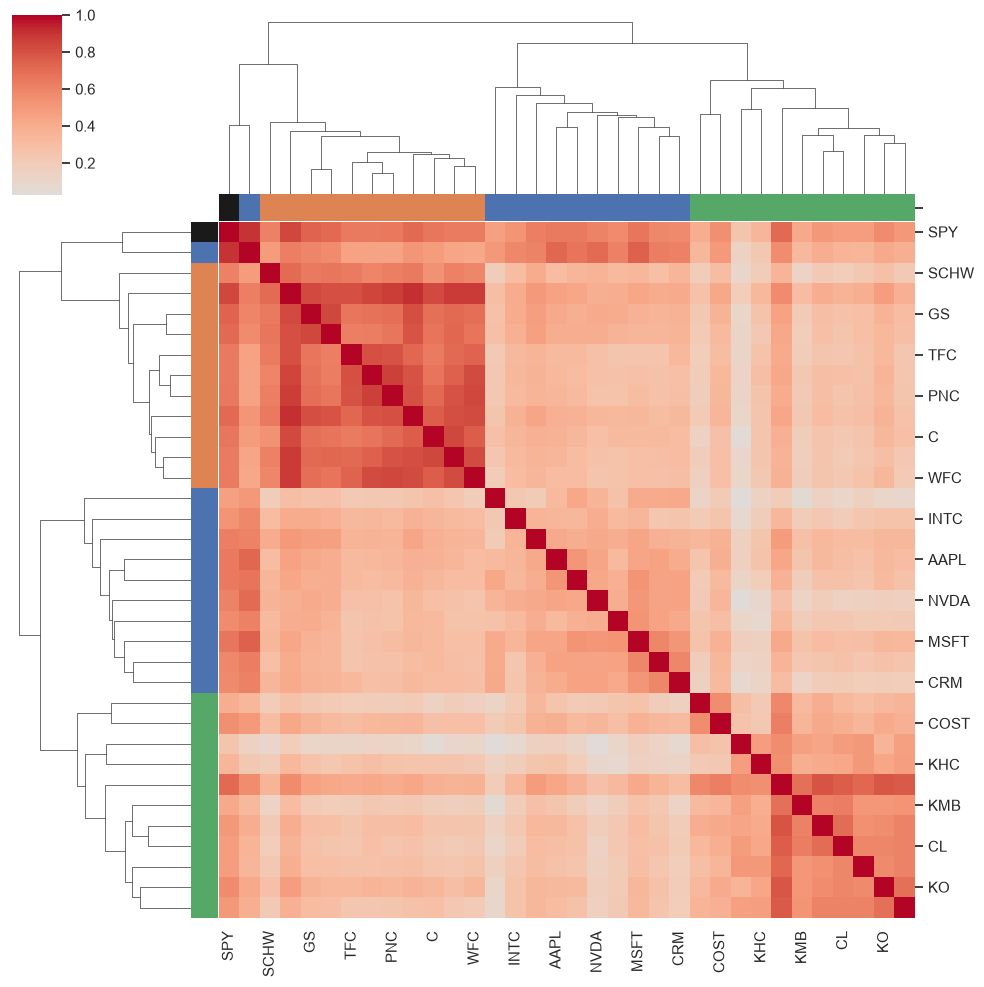

Correlación media entre acciones de la MISMA industria: 0.526 | de industrias DISTINTAS: 0.261
{'tecnologia': 0.404, 'consumo_defensivo': 0.457, 'financiero': 0.718}
ARI (3 clústeres jerárquicos vs. industria): 0.898
clúster             1  2   3
industria                   
consumo_defensivo  10  0   0
financiero          0  0  10
tecnologia          0  9   1
Fuera de su industria: ['INTC'] | correlación XLF-JPM 0.91 | XLK-NVDA 0.71 | SPY-XLK 0.9


In [32]:
from sklearn.metrics import adjusted_rand_score
from scipy.cluster.hierarchy import linkage, fcluster
CR = RET.corr()
ind_ser = pd.Series({t: config.industria_de(t) for t in config.tickers()}); ind_ser = pd.concat([ind_ser, pd.Series({"SPY": "mercado", "XLF": "ETF financiero", "XLK": "ETF tecnología", "XLP": "ETF consumo"})])
col_lat = ind_ser.map({"tecnologia": "C0", "consumo_defensivo": "C2", "financiero": "C1", "mercado": "k", "ETF financiero": "C1", "ETF tecnología": "C0", "ETF consumo": "C2"})
cg = sns.clustermap(CR.loc[ind_ser.index, ind_ser.index], cmap="coolwarm", center=0, figsize=(10, 10), row_colors=col_lat, col_colors=col_lat, method="average")
cg.fig.savefig(config.DIR_ASSETS / "nb04_clustermap_retornos.png", dpi=150, bbox_inches="tight"); plt.show()
acc = list(config.tickers()); A = CR.loc[acc, acc].values; mask = np.triu(np.ones_like(A, bool), 1)
mis = np.array([[ind_ser[a] == ind_ser[b] for b in acc] for a in acc])
print("Correlación media entre acciones de la MISMA industria:", round(A[mask & mis].mean(), 3), "| de industrias DISTINTAS:", round(A[mask & ~mis].mean(), 3))
print({r: round(float(CR.loc[g, g].values[np.triu(np.ones((len(g),) * 2, bool), 1)].mean()), 3) for r, g in config.UNIVERSO.items()})
Z = linkage(1 - CR.loc[acc, acc].values[np.triu_indices(30, 1)], method="average"); cl3 = fcluster(Z, 3, "maxclust")
print("ARI (3 clústeres jerárquicos vs. industria):", round(adjusted_rand_score(ind_ser[acc], cl3), 3))
print(pd.crosstab(ind_ser[acc].values, cl3, rownames=["industria"], colnames=["clúster"]))
print("Fuera de su industria:", [t for t, c in zip(acc, cl3) if ind_ser[t] == "tecnologia" and c != 2], "| correlación XLF-JPM", round(CR.loc["XLF", "JPM"], 2), "| XLK-NVDA", round(CR.loc["XLK", "NVDA"], 2), "| SPY-XLK", round(CR.loc["SPY", "XLK"], 2))

**Lectura (clustermap):** las industrias se agrupan solas. La correlación media entre acciones de la misma industria es 0.526 (financieras 0.718, consumo defensivo 0.457, tecnología 0.404) frente a 0.261 entre industrias distintas. Al cortar el dendrograma en 3 clústeres, el índice de Rand ajustado respecto a la industria es 0.898: las 10 de consumo defensivo y las 10 financieras quedan juntas y 9 de 10 tecnológicas también; la excepción es INTC. Los ETF se ubican junto a sus acciones (correlación XLF-JPM 0.91, XLK-NVDA 0.71) y SPY queda cerca de XLK (0.90). Esto respalda usar el ETF sectorial como factor (HP3), aunque el factor común de mercado también aparece en las correlaciones entre sectores.

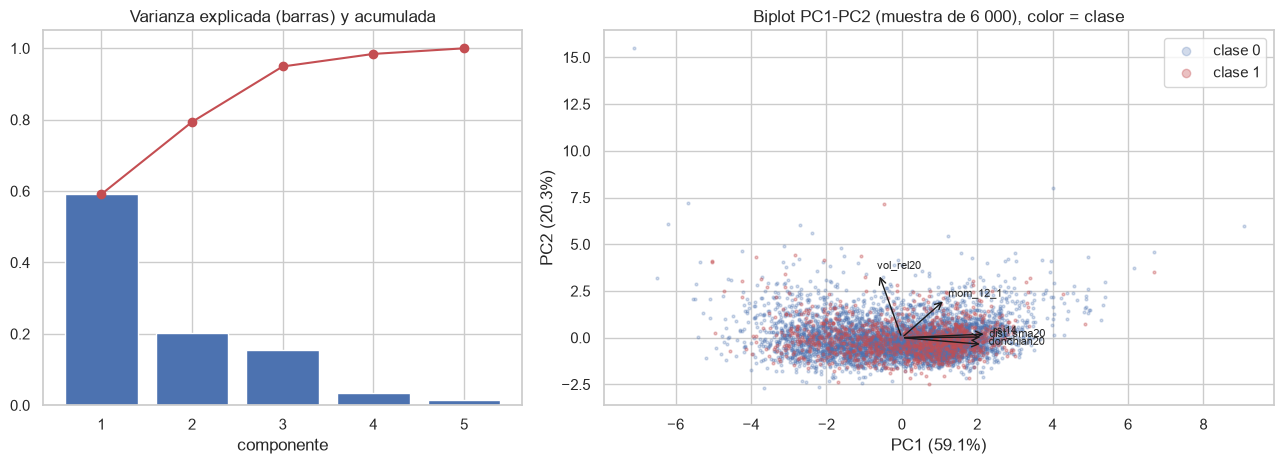

Indicadores: ['rsi14', 'dist_sma20', 'vol_rel20', 'donchian20', 'mom_12_1'] | varianza explicada: [0.591, 0.203, 0.155, 0.035, 0.016] | acumulada 2 PC: 0.794 | 3 PC: 0.949
Cargas:
                PC1     PC2
rsi14       0.5600  0.0500
dist_sma20  0.5400  0.0100
vol_rel20  -0.1500  0.8500
donchian20  0.5400 -0.0900
mom_12_1    0.2900  0.5100


Medias de PC1 y PC2 por clase:
            PC1     PC2
0.0000 -0.0010 -0.0020
1.0000  0.0040  0.0090
AUC de PC1 y PC2 frente a la etiqueta: {'PC1': 0.503, 'PC2': 0.507}


In [33]:
from sklearn.decomposition import PCA
X = D[sel]; Xs = (X - X.mean()) / X.std()
pca = PCA().fit(Xs); ev = pca.explained_variance_ratio_; sc = pca.transform(Xs)
carga = pd.DataFrame(pca.components_[:2].T, index=sel, columns=["PC1", "PC2"])
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1, 1.4]})
ax[0].bar(range(1, len(ev) + 1), ev); ax[0].plot(range(1, len(ev) + 1), ev.cumsum(), "o-", c="C3"); ax[0].set(title="Varianza explicada (barras) y acumulada", xlabel="componente")
m = np.random.default_rng(0).choice(len(D), 6000, replace=False); y = D[Y].to_numpy()[m]
ax[1].scatter(sc[m][y == 0, 0], sc[m][y == 0, 1], s=4, alpha=.25, c="C0", label="clase 0"); ax[1].scatter(sc[m][y == 1, 0], sc[m][y == 1, 1], s=4, alpha=.35, c="C3", label="clase 1")
for c in sel: ax[1].annotate("", xy=carga.loc[c] * 4, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="k")); ax[1].text(*(carga.loc[c] * 4.3), c, fontsize=8)
ax[1].set(title="Biplot PC1-PC2 (muestra de 6 000), color = clase", xlabel=f"PC1 ({ev[0]:.1%})", ylabel=f"PC2 ({ev[1]:.1%})"); ax[1].legend(markerscale=3)
fig.tight_layout(); fig.savefig(config.DIR_ASSETS / "nb04_pca_indicadores.png", dpi=150, bbox_inches="tight"); plt.show()
print("Indicadores:", sel, "| varianza explicada:", ev.round(3).tolist(), "| acumulada 2 PC:", round(ev[:2].sum(), 3), "| 3 PC:", round(ev[:3].sum(), 3))
print("Cargas:\n", carga.round(2).to_string())
print("Medias de PC1 y PC2 por clase:\n", pd.DataFrame(sc[:, :2], columns=["PC1", "PC2"]).groupby(y_all := D[Y].values).mean().round(3).to_string())
print("AUC de PC1 y PC2 frente a la etiqueta:", {f"PC{i+1}": round(roc_auc_score(D[Y], sc[:, i]), 3) for i in range(2)})

**Lectura (PCA):** con los 5 indicadores conservados (tras E2), los dos primeros componentes explican 79.4 % de la varianza (PC1 59.1 %, PC2 20.3 %; tres componentes, 94.9 %). PC1 es un eje de "sobreextensión" (cargas 0.56 en RSI, 0.54 en distancia a la SMA20 y 0.54 en Donchian) y PC2 está dominado por el volumen relativo (0.85) con algo de momentum (0.51). Las clases de la etiqueta se superponen casi por completo en el biplot (medias de PC1: −0.001 en clase 0 y 0.004 en clase 1) y la AUC de PC1 y PC2 es 0.503 y 0.507: la reducción de dimensión no separa las clases, en línea con HT2 no concluyente.

**Justificación (PCA).** Se estandarizan los indicadores (escalas distintas) y se usan los 5 conservados en E2 para no inflar un componente con indicadores colineales. El PCA se usa para describir la estructura, no como entrada del modelo.

**Síntesis (correlaciones y PCA).**
- Las industrias se agrupan solas por correlación de retornos (ARI 0.898; correlación intra-industria 0.526 frente a 0.261 entre industrias).
- Los indicadores tienen pocas dimensiones independientes (2 componentes: 79.4 %) y ninguna separa las clases (AUC 0.503 a 0.507).
- **Decisión que alimenta:** el factor sectorial es legítimo en la simulación; el SVM debe esperar poca señal lineal en los indicadores y evaluarse con rigor frente a la línea base.

## 10. HF4 (secundaria): distancia al default de Merton
**HF4.** Menor distancia al default (d₂) se asocia con mayor riesgo de caída. Para cada ticker no financiero y año fiscal se resuelve `rg.merton` con E = cierre ajustado por splits (`precios_semanales_sd`) × acciones ajustadas por splits en la semana de publicación (`filed`), σ_E = volatilidad anual de las 52 semanas previas, D = `deuda_lp` y r = 0.04 (T = 1). Las financieras se excluyen porque su deuda es parte de su negocio y el modelo no aplica. La asociación se mide con Spearman frente al drawdown mínimo de las 52 semanas siguientes (solo información posterior a `filed`, uso asociativo, no predictivo). Las observaciones del mismo ticker se solapan y son dependientes, por lo que los p-valores son orientativos.

Observaciones ticker-año: 216 | con d2 válido: 216 | tickers: 17 | d2 mediana: 14.08 | PD mediana: 2.54e-45
Spearman d2 vs. drawdown siguiente 52s (todas): rho=0.171 p=0.0119 n=216
  consumo_defensivo: rho=-0.056 p=0.543 n=121
  tecnologia: rho=0.071 p=0.491 n=95
Sin observaciones (GOOGL sin acciones; sin deuda_lp > 0 o historia corta): ['GOOGL', 'ORCL', 'KHC']
d2 por industria (mediana, rango p10-p90): {'consumo_defensivo': '16.4 (10.9-20.8)', 'tecnologia': '12.1 (7.8-16.8)'}
Cuartil inferior de d2 (<= 11.2) vs. superior: drawdown mediano -0.089 vs. -0.051
ESTADO HF4: no concluyente


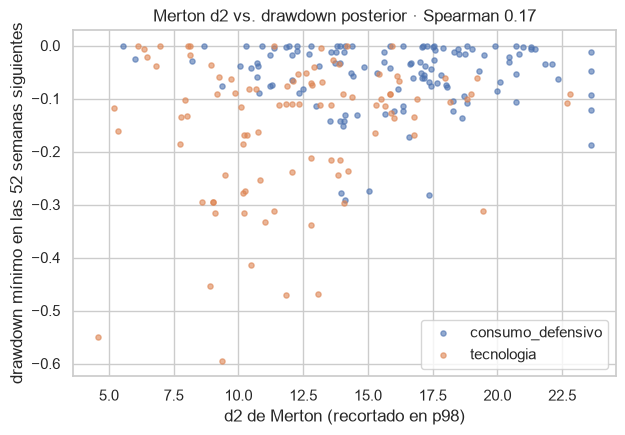

In [34]:
# Merton por ticker no financiero y año fiscal; E = close_sd × acciones (ajustadas por splits) en la fecha filed; sigma_E de los 52 retornos previos
FIN = set(config.UNIVERSO["financiero"]); filas = []
for t in [x for x in config.tickers() if x not in FIN and x != "GOOGL"]:
    rt = fu.ajustar_por_splits(rat[rat.ticker == t], splits[splits.ticker == t]).dropna(subset=["filed"])
    px = ancho_sd[t].dropna(); r_t = RET[t].dropna()
    for _, f in rt.iterrows():
        i = px.index.searchsorted(f.filed)
        if i >= len(px) - 52 or i < 52 or not (f.acciones > 0 and f.deuda_lp > 0): continue
        E_ = px.iloc[i] * f.acciones; fecha = px.index[i]
        sE = r_t[:fecha].iloc[-52:].std() * np.sqrt(52)
        m = rg.merton(E=E_, sigma_E=sE, D=f.deuda_lp, r=0.04)
        dd_sig = (cl[t].loc[fecha:].iloc[:53] / cl[t].loc[fecha] - 1).min()   # drawdown mínimo de las 52 semanas siguientes (precio ajustado)
        filas.append(dict(ticker=t, industria=config.industria_de(t), fecha=fecha, E=E_, D=f.deuda_lp, sigma_E=sE, d2=m["d2"], pd=m["pd"], dd_sig=dd_sig))
mer = pd.DataFrame(filas); mer["valido"] = mer.d2.notna()
print("Observaciones ticker-año:", len(mer), "| con d2 válido:", int(mer.valido.sum()), "| tickers:", mer.ticker.nunique(), "| d2 mediana:", round(mer.d2.median(), 2), "| PD mediana:", f"{mer.pd.median():.2e}")
mv = mer[mer.valido]; rho, p = stats.spearmanr(mv.d2, mv.dd_sig)
print(f"Spearman d2 vs. drawdown siguiente 52s (todas): rho={rho:.3f} p={p:.3g} n={len(mv)}")
rho_ind = {}
for ramo, g in mv.groupby("industria"):
    r_, p_ = stats.spearmanr(g.d2, g.dd_sig); rho_ind[ramo] = (r_, p_); print(f"  {ramo}: rho={r_:.3f} p={p_:.3g} n={len(g)}")
sin_obs = [x for x in config.tickers() if x not in FIN and x not in mer.ticker.unique()]
print("Sin observaciones (GOOGL sin acciones; sin deuda_lp > 0 o historia corta):", sin_obs)
print("d2 por industria (mediana, rango p10-p90):", mv.groupby("industria").d2.agg(lambda s: f"{s.median():.1f} ({s.quantile(.1):.1f}-{s.quantile(.9):.1f})").to_dict())
print("Cuartil inferior de d2 (<= %.1f) vs. superior: drawdown mediano %.3f vs. %.3f" % (mv.d2.quantile(.25), mv.dd_sig[mv.d2 <= mv.d2.quantile(.25)].median(), mv.dd_sig[mv.d2 >= mv.d2.quantile(.75)].median()))
# Estado de HF4 (regla general de los cuatro estados): apoyada solo si el signo esperado (rho > 0) es significativo en la muestra global y en cada industria;
# si es significativo solo en la global (p supone independencia, sin IC por bloques) no es concluyente; si no hay asociación en el sentido esperado, no apoyada
sig_g = (rho > 0) and (p < 0.05); sig_i = all((r_ > 0) and (p_ < 0.05) for r_, p_ in rho_ind.values())
ESTADO_HF4 = "apoyada" if (sig_g and sig_i) else ("no concluyente" if sig_g else "no apoyada")
print("ESTADO HF4:", ESTADO_HF4)
fig, ax = plt.subplots(figsize=(7, 4.5))
for ramo, g in mv.groupby("industria"): ax.scatter(g.d2.clip(upper=mv.d2.quantile(.98)), g.dd_sig, s=14, alpha=.6, label=ramo)
ax.set(xlabel="d2 de Merton (recortado en p98)", ylabel="drawdown mínimo en las 52 semanas siguientes", title=f"Merton d2 vs. drawdown posterior · Spearman {rho:.2f}"); ax.legend()
fig.savefig(config.DIR_ASSETS / "nb04_merton_d2_drawdown.png", dpi=150, bbox_inches="tight"); plt.show()

**Lectura (Merton):** hay 216 observaciones ticker-año válidas de 17 tickers (GOOGL, ORCL y KHC no entran). El d₂ mediano es 14.08 (PD ≈ 10⁻⁴⁵, prácticamente cero): la `deuda_lp` es pequeña frente al valor de mercado de estas empresas grandes, por lo que el nivel absoluto de PD no es informativo y solo se usa el orden. La correlación de Spearman entre d₂ y el drawdown de las 52 semanas siguientes es +0.171 (p = 0.012, n = 216): a menor d₂, caída máxima más profunda (mediana −0.089 en el cuartil inferior de d₂ frente a −0.051 en el superior). Dentro de cada industria desaparece (consumo defensivo −0.056, p = 0.54; tecnología +0.071, p = 0.49), así que la asociación global viene en buena parte de diferencias entre industrias y años.

**Justificación y síntesis (HF4).** Se usa solo deuda de largo plazo porque es el concepto disponible y comparable en EDGAR; es una limitación (sub-estima la deuda total), por lo que d₂ es un indicador de apalancamiento relativo y no una probabilidad de quiebra calibrada. **HF4: no concluyente.** No tiene fila propia en 4.4, así que se aplica la definición general de los cuatro estados: el signo es el esperado en la muestra global (ρ = +0.171, p = 0.012), pero ese p supone observaciones independientes (son ticker-años de los mismos emisores y años), no hay IC por bloques, y dentro de cada industria la asociación desaparece (p = 0.54 y 0.49). La evidencia no permite apoyarla ni descartarla. **Decisión que alimenta:** d₂ no se usa como señal; si acaso, como contexto de riesgo en la ficha del emisor.

## 10b. HF3 (secundaria, exploratoria): valoración, calidad y retorno posterior
**HF3.** Estar barata frente a su historia y a su industria, con calidad, se asocia con mejores retornos a 12 meses. Para cada ticker y semana se promedian el percentil del múltiplo en su propia historia (expansivo, solo datos ≤ t) y su percentil dentro de la industria en esa fecha (ambos con la serie P/E o P/B sin look-ahead, alineada por `filed`); ese promedio se divide en quintiles (1 = más barato). La calidad es ROE por encima de la mediana de la industria en la misma fecha (último dato publicado). Se mide el retorno logarítmico de las siguientes 52 semanas y el Spearman entre percentil y retorno, con IC 95 % por *block bootstrap* de bloques de 52 semanas de fechas (300 réplicas, semilla 42). **Es exploratoria:** son 29 tickers de 3 industrias, con ≈ 15 ventanas independientes de 52 semanas por ticker, un solo ciclo de mercado dominante y ventanas solapadas; los intervalos son anchos y el resultado es asociativo.

Observaciones ticker-semana: 20820 | tickers: 29 | ventanas independientes de 52 semanas por ticker ≈ 14.6
          mean        median        count      
calidad  False  True   False  True  False True 
quintil                                        
1       0.1310 0.1450 0.1600 0.1490  2524  1640
2       0.1100 0.1420 0.1280 0.1370  2347  1817
3       0.1010 0.1160 0.1120 0.1010  2114  2050
4       0.1290 0.1450 0.1090 0.1270  1693  2471
5       0.2130 0.1080 0.1690 0.1260  1980  2184


                  n     rho   ic_lo  ic_hi
grupo                                     
todas         20820  0.0010 -0.0930 0.0640
calidad alta  10162 -0.0450 -0.1340 0.0170
calidad baja  10658  0.0360 -0.1050 0.1140


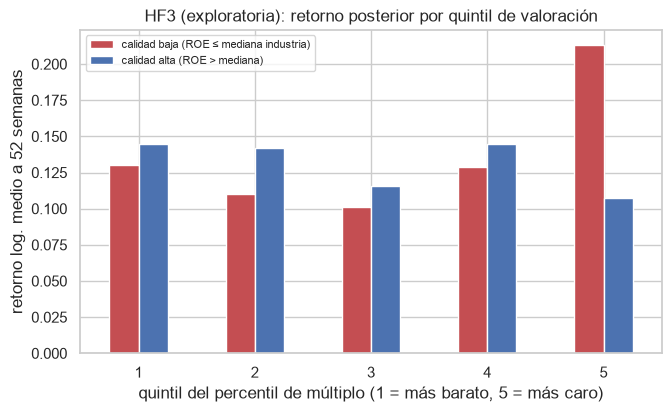

In [35]:
PCT_HIST = MULT.apply(fu.percentil_expansivo)                       # percentil en su propia historia (solo datos <= t)
fwd = np.log(cl).shift(-52) - np.log(cl)                            # retorno logarítmico de las siguientes 52 semanas (precio ajustado)
roe = {}
for t in MULT.columns:
    r_ = rat[rat.ticker == t].dropna(subset=["filed"]).sort_values("filed")[["filed", "roe"]].astype({"filed": "datetime64[ns]"})
    roe[t] = pd.merge_asof(pd.DataFrame({"fecha": MULT.index.astype("datetime64[ns]")}), r_, left_on="fecha", right_on="filed")["roe"].set_axis(MULT.index)
ROE = pd.DataFrame(roe)
cal = pd.DataFrame({t: ROE[t] > ROE[[x for x in config.UNIVERSO[config.industria_de(t)] if x in ROE]].median(axis=1) for t in ROE})
hf3 = pd.concat({"pct_hist": PCT_HIST.stack(), "pct_ind": PCTG.stack(), "fwd52": fwd[MULT.columns].stack(), "calidad": cal.where(ROE.notna()).stack()}, axis=1).dropna()
hf3["pctl"] = (hf3.pct_hist + hf3.pct_ind) / 2; hf3["quintil"] = pd.qcut(hf3.pctl, 5, labels=False) + 1
hf3 = hf3.reset_index(); hf3.columns = ["fecha", "ticker"] + list(hf3.columns[2:])
print("Observaciones ticker-semana:", len(hf3), "| tickers:", hf3.ticker.nunique(), "| ventanas independientes de 52 semanas por ticker ≈", round(hf3.groupby("ticker").size().median() / 52, 1))
tab = hf3.groupby(["quintil", "calidad"]).fwd52.agg(["mean", "median", "count"]).unstack("calidad"); print(tab.round(3).to_string())
def spear(d): return stats.spearmanr(d.pctl, d.fwd52)[0]
rng = np.random.default_rng(42); fechas = np.sort(hf3.fecha.unique()); L = 52; grupos = {f: g for f, g in hf3.groupby("fecha")}
def boot(d, reps=300):
    fe = np.sort(d.fecha.unique()); out = []; dd = {f: g for f, g in d.groupby("fecha")}
    for _ in range(reps):
        ini = rng.integers(0, len(fe) - L, size=int(np.ceil(len(fe) / L)))
        out.append(spear(pd.concat([dd[f] for i in ini for f in fe[i:i + L]])))
    return np.percentile(out, [2.5, 97.5])
res = []
for nombre, d in [("todas", hf3), ("calidad alta", hf3[hf3.calidad == 1]), ("calidad baja", hf3[hf3.calidad == 0])]:
    lo, hi = boot(d); res.append(dict(grupo=nombre, n=len(d), rho=spear(d), ic_lo=lo, ic_hi=hi))
res = pd.DataFrame(res).set_index("grupo"); print(res.round(3).to_string())
fig, ax = plt.subplots(figsize=(7.5, 4.2)); tab["mean"].plot.bar(ax=ax, rot=0, color=["C3", "C0"]); ax.legend(["calidad baja (ROE ≤ mediana industria)", "calidad alta (ROE > mediana)"], fontsize=8)
ax.set(xlabel="quintil del percentil de múltiplo (1 = más barato, 5 = más caro)", ylabel="retorno log. medio a 52 semanas", title="HF3 (exploratoria): retorno posterior por quintil de valoración")
fig.savefig(config.DIR_ASSETS / "nb04_hf3_quintiles.png", dpi=150, bbox_inches="tight"); plt.show()

**Lectura (HF3):** hay 20 820 observaciones ticker-semana de 29 tickers (≈ 14.6 ventanas independientes por ticker). El retorno medio a 52 semanas es 0.131 y 0.145 en el quintil más barato (calidad baja y alta) y 0.213 y 0.108 en el más caro, sin un patrón monótono. El Spearman entre el percentil de valoración y el retorno posterior es 0.001 (IC 95 % −0.093 a 0.064) en toda la muestra, −0.045 (−0.134 a 0.017) en calidad alta y 0.036 (−0.105 a 0.114) en calidad baja: los tres intervalos contienen el 0. El quintil más caro con calidad baja rinde más (0.213), un resultado más compatible con empresas de crecimiento ganadoras en la muestra (sesgo de supervivencia) que con una prima de valor.

**Justificación y síntesis (HF3).** Se separa por ROE frente a la industria (y no por ROIC, ausente en financieras) para tener una definición única de calidad. **HF3: no concluyente (exploratoria).** No tiene fila propia en 4.4; por la definición general, un IC que incluye el valor nulo es no concluyente, y aquí los tres IC del Spearman incluyen 0: no hay asociación detectable entre baratura y retorno posterior, con o sin calidad, y la muestra es demasiado pequeña para descartar efectos moderados. **Decisión que alimenta:** el percentil de múltiplo no se promete como señal de entrada; queda como contexto descriptivo en la ficha.

## 11. Matriz de cobertura de técnicas y estado de las hipótesis
**Matriz de cobertura.** Cada celda reúne las técnicas aplicadas y el notebook y sección donde están (nb02 = calidad, nb03 = series, nb04 = relaciones).

| | **Gráfica** | **No gráfica** |
|---|---|---|
| **Univariada** | Series y retornos de 3 tickers (nb03 §1); QQ-plots normal y t (nb03 §3); ACF de r y r² (nb03 §4); volatilidad EWMA y GARCH (nb03 §5); STL mensual (nb03 §7); múltiplo y percentil expansivo (nb03 §8); múltiplo relativo en el tiempo (nb04 §8) | Hechos estilizados en 34 series: asimetría, curtosis, Jarque-Bera, ajuste t (nb03 §2); Ljung-Box y ARCH-LM (nb03 §4-5); ADF y KPSS (nb03 §6); ajuste OU del múltiplo relativo (nb04 §8); auditoría de calidad por dimensión, saltos de 5σ y censura (nb02 §1, §2, §6); VaR, ES, drawdown y Sharpe (nb03 §9); ADF y OU del múltiplo a su historia (nb03, bloque de múltiplos) |
| **Multivariada** | Clustermap de correlaciones de retornos (nb04 §9); PCA y biplot (nb04 §9); heatmap de Spearman entre indicadores (nb04 §5); AUC por régimen (nb04 §6); boxplots de indicadores por clase (bivariada, nb04 §4); calibración del GBM por decil de σ, observada frente a modelo (bivariada, nb04 §3); R² y varianza sistemática por ticker y β móvil frente al ETF (nb04 §7); mapa de completitud EDGAR concepto × ticker (nb02 §3); dispersión d₂ frente a drawdown (nb04 §10); quintiles de valoración por calidad (nb04 §10b) | AUC de cada indicador frente a la etiqueta y bootstrap por fechas (bivariada, nb04 §4); regresión de índice único: β, α, R² y σ idiosincrática (nb04 §7); simulación con y sin sector (nb04 §7); VIF e información mutua (nb04 §5, §4); Mann-Whitney y *block bootstrap* (nb04 §4); correlación de Spearman con bootstrap (nb04 §10, §10b); modelo de Merton (nb04 §10); triangulación con diferencias relativas (nb02 §4); múltiplo relativo frente a Damodaran (nb04 §8) |

In [36]:
from IPython.display import Markdown, display
r_all = res.loc["todas"]
NOM = {"tecnologia": "tecnología", "consumo_defensivo": "consumo defensivo", "financiero": "financieros"}
cal_d = tab_calib.loc["GBM con deriva ≤ t"]
ESTADO_HF3 = "no concluyente" if r_all.ic_lo <= 0 <= r_all.ic_hi else ("apoyada" if r_all.ic_hi < 0 else "no apoyada")   # IC que incluye 0 -> no concluyente
# Estados de nb03 (no se pueden importar sus variables): se copian de las salidas de nb03 §6, §8, §5, §3-5 y §9b
estado = [
 ("HT0 (caminata aleatoria)", "Los log-precios siguen una caminata aleatoria (línea base)",
  "Por ticker: ADF no rechaza, KPSS rechaza y LB(r) no rechaza; en más de la mitad de cada industria",
  "nb03 §6: pasan 15 de 30 (tecnología 8/10, consumo defensivo 5/10, financieros 2/10)", "no apoyada",
  "LB sobre residuos estandarizados de GARCH-t (la dependencia de r se asocia con la volatilidad): pasarían 26 de 30 (9/10, 7/10, 10/10); la regla no lo contempla"),
 ("HT0 (calibración de P_GBM)", "P_GBM es una probabilidad calibrada",
  "Calibrada si IC 95 % de a ∋ 0 e IC de b ∋ 1 (logit de la etiqueta sobre logit P_GBM)",
  f"nb04 §3, deriva ≤ t: a = {cal_d.a:.3f} (IC {cal_d.a_IC_inf:.3f} a {cal_d.a_IC_sup:.3f}), b = {cal_d.b:.3f} (IC {cal_d.b_IC_inf:.3f} a {cal_d.b_IC_sup:.3f}); con μ = 0 tampoco", ESTADO_HT0_CAL,
  "—"),
 ("HT1", "El SVM mejora la línea base (GBM con deriva ≤ t y tasa por decil de σ_t)",
  "ΔAUC y ΔBrier > 0 con IC que excluye 0", "nb04 §2-3: etiqueta k = 1, N = 12 y línea base listas; el SVM se evalúa en la entrega final", "preparada", "—"),
 ("HT2", "Sobreextensión se asocia con retroceso",
  "Por indicador: IC por fechas excluye 0.5, p_BH < 0.05 y sentido esperado (bilateral en vol_rel20 y mom_12_1); convención: ≥ 1 asociado → apoyada",
  f"nb04 §4: {int(r2t.asociado.sum())} de {len(r2t)} asociados; AUC {tab_auc.AUC.min():.3f} a {tab_auc.AUC.max():.3f}; los {int((~r2t['IC_excluye_0.5']).sum())} IC por fechas incluyen 0.5; p_BH < 0.05 en RSI, vol_rel20 y mom_12_1", ESTADO_HT2, "—"),
 ("HT3", "Relación indicador → etiqueta estable entre regímenes",
  "Signo de AUC − 0.5 se mantiene en la mayoría de los regímenes con muestra suficiente; convención: estable en todos los indicadores analizados",
  "nb04 §6: " + ", ".join(f"{i} {r.coinciden}/{r.regimenes}" for i, r in ht3_t.iterrows()), ESTADO_HT3,
  f"Con mayoría de indicadores ({int(ht3_t.estable.sum())} de {len(ht3_t)} estables) sería {ALT_HT3}; los 3 indicadores son los 3 de mayor distancia de la AUC a 0.5 en §4 (selección post hoc); "
  f"los signos son puntuales ({ic_con_05} de {n_reg_ev} IC por régimen calculados incluyen 0.5; {n_sin_ic} celdas son puntos sin IC); la magnitud cambia (≈ 0.51 frente a 0.64 a 0.79 en COVID y 2022)"),
 ("HT4", "La volatilidad se agrupa", "Sin fila propia en 4.4; ARCH-LM y persistencia del GARCH (como HP0)",
  "nb03 §5: ARCH-LM 85.3 % de las series; persistencia mediana 0.943", "apoyada", "—"),
 ("HF1", "Los múltiplos revierten a su historia",
  "Por empresa: ADF < 0.05, η > 0 y vida media < mitad de la historia; más de la mitad por industria",
  "nb03 §8: 7 de 29 (tecnología 2/9, consumo defensivo 3/10, financieros 2/10)", "no apoyada", "—"),
 ("HF2", "El múltiplo relativo a la industria revierte",
  "Igual que HF1, sobre el múltiplo relativo",
  "nb04 §8: " + f"{int(h2.pasa.sum())} de {len(h2)} (" + ", ".join(f"{NOM[i]} {r['pasan los 3']}/{r.evaluables}" for i, r in tab_hf2.iterrows()) + ")", ESTADO_HF2, "—"),
 ("HF3", "Barata y con calidad rinde más (exploratoria)",
  "Sin fila en 4.4; regla general: IC que incluye el valor nulo → no concluyente",
  f"nb04 §10b: Spearman {r_all.rho:.3f} (IC {r_all.ic_lo:.3f} a {r_all.ic_hi:.3f}), n = {int(r_all.n):,}", ESTADO_HF3, "—"),
 ("HF4", "Menor d₂ de Merton se asocia con más caída",
  "Sin fila en 4.4; regla general de los cuatro estados",
  f"nb04 §10: Spearman {rho:.3f} (p = {p:.3f}, descriptivo, n = {len(mv)}); dentro de industria " + ", ".join(f"{NOM[i]} {r_:+.3f} (p = {p_:.2f})" for i, (r_, p_) in rho_ind.items()), ESTADO_HF4,
  "—"),
 ("HF5", "Ratios EDGAR consistentes con otras fuentes", "Sin fila en 4.4; auditoría de nb02",
  "nb02 §4: 6 de 6 cifras coinciden con el 10-K de AAPL, KO y JPM", "apoyada", "—"),
 ("HP0", "El GBM normal no es adecuado (colas pesadas, ARCH)",
  "GBM adecuado si ARCH-LM y LB(r²) no rechazan; si ARCH-LM rechaza en más de la mitad, GARCH-t",
  "nb03 §3-5: ARCH-LM 85.3 %, LB(r²) 88.2 %; curtosis en exceso mediana 4.63; ν mediano 4.15", "apoyada", "—"),
 ("HP1", "GARCH-t describe mejor el riesgo que el GBM normal",
  "Kupiec e independencia sin rechazo al 5 %; más de la mitad por industria",
  "nb03 §9b: GARCH-t adecuado en 14 de 30 (tecnología 3/10, consumo defensivo 5/10, financieros 6/10); histórico 19 de 30", "no apoyada",
  "—"),
 ("HP2", "Probabilidades Monte Carlo calibradas", "Brier y calibración walk-forward",
  "nb04 §7: simulación de índice único lista; la calibración walk-forward es de la entrega final", "preparada", "—"),
 ("HP3", "El ETF sectorial explica buena parte del movimiento",
  "IC de β excluye 0 y R² mediano ≥ 0.30 en cada industria",
  f"nb04 §7: IC de β excluye 0 en {int(ic_beta.excluye_0.sum())} de {len(ic_beta)}; R² mediano " + ", ".join(f"{NOM[i]} {r:.3f}" for i, r in reg_hp3.r2_mediana.items()), ESTADO_HP3,
  "—"),
]
tb = pd.DataFrame(estado, columns=["ID", "Hipótesis", "Regla (4.4)", "Resultado con cifra", "Estado según la regla", "Desviación documentada"])
tb["Estado final"] = tb["Estado según la regla"]
assert tb["Estado final"].isin(["apoyada", "no apoyada", "no concluyente", "preparada"]).all()
NOTAS = ("**Notas a la columna \"Desviación documentada\".** HT0 (calibración): sesgo reportado, P media " f"{CAL.p_deriva.mean():.4f} frente a {CAL.y_k1_n12.mean():.4f} observada y orden entre filas invertido (b < 0). "
         "HF4: el p global supone independencia y la asociación desaparece dentro de industria. "
         "HP1: las colas pesadas sí están evidenciadas (ν < 10 en 34 de 34), pero la regla decide con el backtest. "
         "HP3: matiz por régimen, tecnología en Reciente 0.283 < 0.30.")
display(Markdown("| " + " | ".join(tb.columns) + " |\n|" + "---|" * len(tb.columns) + "\n" + "\n".join("| " + " | ".join(map(str, f)) + " |" for f in tb.values)))
display(Markdown(NOTAS))
print("Filas:", len(tb), "(14 hipótesis; HT0 en dos filas)")
print(tb["Estado final"].value_counts().to_string())
print({e: list(tb.ID[tb["Estado final"] == e]) for e in ["apoyada", "no apoyada", "no concluyente", "preparada"]})

| ID | Hipótesis | Regla (4.4) | Resultado con cifra | Estado según la regla | Desviación documentada | Estado final |
|---|---|---|---|---|---|---|
| HT0 (caminata aleatoria) | Los log-precios siguen una caminata aleatoria (línea base) | Por ticker: ADF no rechaza, KPSS rechaza y LB(r) no rechaza; en más de la mitad de cada industria | nb03 §6: pasan 15 de 30 (tecnología 8/10, consumo defensivo 5/10, financieros 2/10) | no apoyada | LB sobre residuos estandarizados de GARCH-t (la dependencia de r se asocia con la volatilidad): pasarían 26 de 30 (9/10, 7/10, 10/10); la regla no lo contempla | no apoyada |
| HT0 (calibración de P_GBM) | P_GBM es una probabilidad calibrada | Calibrada si IC 95 % de a ∋ 0 e IC de b ∋ 1 (logit de la etiqueta sobre logit P_GBM) | nb04 §3, deriva ≤ t: a = -1.983 (IC -2.672 a -1.429), b = -0.294 (IC -0.641 a -0.011); con μ = 0 tampoco | no apoyada | — | no apoyada |
| HT1 | El SVM mejora la línea base (GBM con deriva ≤ t y tasa por decil de σ_t) | ΔAUC y ΔBrier > 0 con IC que excluye 0 | nb04 §2-3: etiqueta k = 1, N = 12 y línea base listas; el SVM se evalúa en la entrega final | preparada | — | preparada |
| HT2 | Sobreextensión se asocia con retroceso | Por indicador: IC por fechas excluye 0.5, p_BH < 0.05 y sentido esperado (bilateral en vol_rel20 y mom_12_1); convención: ≥ 1 asociado → apoyada | nb04 §4: 0 de 7 asociados; AUC 0.496 a 0.514; los 7 IC por fechas incluyen 0.5; p_BH < 0.05 en RSI, vol_rel20 y mom_12_1 | no concluyente | — | no concluyente |
| HT3 | Relación indicador → etiqueta estable entre regímenes | Signo de AUC − 0.5 se mantiene en la mayoría de los regímenes con muestra suficiente; convención: estable en todos los indicadores analizados | nb04 §6: vol_rel20 2/5, mom_12_1 3/4, rsi14 5/5 | no apoyada | Con mayoría de indicadores (2 de 3 estables) sería apoyada; los 3 indicadores son los 3 de mayor distancia de la AUC a 0.5 en §4 (selección post hoc); los signos son puntuales (6 de 6 IC por régimen calculados incluyen 0.5; 8 celdas son puntos sin IC); la magnitud cambia (≈ 0.51 frente a 0.64 a 0.79 en COVID y 2022) | no apoyada |
| HT4 | La volatilidad se agrupa | Sin fila propia en 4.4; ARCH-LM y persistencia del GARCH (como HP0) | nb03 §5: ARCH-LM 85.3 % de las series; persistencia mediana 0.943 | apoyada | — | apoyada |
| HF1 | Los múltiplos revierten a su historia | Por empresa: ADF < 0.05, η > 0 y vida media < mitad de la historia; más de la mitad por industria | nb03 §8: 7 de 29 (tecnología 2/9, consumo defensivo 3/10, financieros 2/10) | no apoyada | — | no apoyada |
| HF2 | El múltiplo relativo a la industria revierte | Igual que HF1, sobre el múltiplo relativo | nb04 §8: 10 de 29 (tecnología 3/9, consumo defensivo 5/10, financieros 2/10) | no apoyada | — | no apoyada |
| HF3 | Barata y con calidad rinde más (exploratoria) | Sin fila en 4.4; regla general: IC que incluye el valor nulo → no concluyente | nb04 §10b: Spearman 0.001 (IC -0.093 a 0.064), n = 20,820 | no concluyente | — | no concluyente |
| HF4 | Menor d₂ de Merton se asocia con más caída | Sin fila en 4.4; regla general de los cuatro estados | nb04 §10: Spearman 0.171 (p = 0.012, descriptivo, n = 216); dentro de industria consumo defensivo -0.056 (p = 0.54), tecnología +0.071 (p = 0.49) | no concluyente | — | no concluyente |
| HF5 | Ratios EDGAR consistentes con otras fuentes | Sin fila en 4.4; auditoría de nb02 | nb02 §4: 6 de 6 cifras coinciden con el 10-K de AAPL, KO y JPM | apoyada | — | apoyada |
| HP0 | El GBM normal no es adecuado (colas pesadas, ARCH) | GBM adecuado si ARCH-LM y LB(r²) no rechazan; si ARCH-LM rechaza en más de la mitad, GARCH-t | nb03 §3-5: ARCH-LM 85.3 %, LB(r²) 88.2 %; curtosis en exceso mediana 4.63; ν mediano 4.15 | apoyada | — | apoyada |
| HP1 | GARCH-t describe mejor el riesgo que el GBM normal | Kupiec e independencia sin rechazo al 5 %; más de la mitad por industria | nb03 §9b: GARCH-t adecuado en 14 de 30 (tecnología 3/10, consumo defensivo 5/10, financieros 6/10); histórico 19 de 30 | no apoyada | — | no apoyada |
| HP2 | Probabilidades Monte Carlo calibradas | Brier y calibración walk-forward | nb04 §7: simulación de índice único lista; la calibración walk-forward es de la entrega final | preparada | — | preparada |
| HP3 | El ETF sectorial explica buena parte del movimiento | IC de β excluye 0 y R² mediano ≥ 0.30 en cada industria | nb04 §7: IC de β excluye 0 en 30 de 30; R² mediano consumo defensivo 0.495, financieros 0.700, tecnología 0.387 | apoyada | — | apoyada |

**Notas a la columna "Desviación documentada".** HT0 (calibración): sesgo reportado, P media 0.1812 frente a 0.1781 observada y orden entre filas invertido (b < 0). HF4: el p global supone independencia y la asociación desaparece dentro de industria. HP1: las colas pesadas sí están evidenciadas (ν < 10 en 34 de 34), pero la regla decide con el backtest. HP3: matiz por régimen, tecnología en Reciente 0.283 < 0.30.

Filas: 15 (14 hipótesis; HT0 en dos filas)
Estado final
no apoyada        6
apoyada           4
no concluyente    3
preparada         2
{'apoyada': ['HT4', 'HF5', 'HP0', 'HP3'], 'no apoyada': ['HT0 (caminata aleatoria)', 'HT0 (calibración de P_GBM)', 'HT3', 'HF1', 'HF2', 'HP1'], 'no concluyente': ['HT2', 'HF3', 'HF4'], 'preparada': ['HT1', 'HP2']}


**Lectura (estado de hipótesis):** la tabla aplica la regla de 4.4 de forma literal y usa solo cuatro estados; HT0 ocupa dos filas, porque 4.4 le da dos reglas (caminata aleatoria y calibración de P_GBM), así que hay 15 filas para 14 hipótesis. Los estados de HT0 (caminata aleatoria), HT4, HF1, HP0 y HP1 se copian de las salidas de nb03 (§5, §6, §8 y §9b); el resto sale de las celdas de este notebook. Resultado: 4 filas apoyadas (HT4, HF5, HP0, HP3), 6 no apoyadas (HT0 caminata aleatoria, HT0 calibración, HT3, HF1, HF2, HP1), 3 no concluyentes (HT2, HF3, HF4) y 2 preparadas (HT1, HP2). El estado final coincide siempre con el de la regla; las desviaciones documentadas (HT0 con Ljung-Box sobre residuos de GARCH-t: 26 de 30; la magnitud de la AUC en HT3) y los matices (HP3 en tecnología, Reciente 0.283; colas pesadas en HP1) no lo cambian. El patrón: lo que describe el riesgo (volatilidad agrupada, colas pesadas, dependencia del sector) se sostiene, mientras que las señales de dirección (indicadores, múltiplos, calidad, d₂) no se apoyan o no son concluyentes, y la línea base GBM no está calibrada.

**Síntesis general (notebook 04).**
- **Etiquetas y línea base:** k = 1 y N = 12 (17.1 % de clase 1 en toda la muestra etiquetada; 17.8 % en la muestra de la línea base con deriva). Con la misma muestra, el GBM con μ = 0 sobreestima la clase 1 en 9.5 pp (0.178 observada frente a 0.274) y el GBM con deriva pasada, en 0.8 pp (los −10.3 pp de §2 corresponden a la muestra completa). Por la regla de 4.4, P_GBM no está calibrada (HT0 calibración no apoyada): el IC de b va de −0.641 a −0.011 con deriva. Sigue siendo el rival del SVM (HT1, preparada), junto con la tasa por decil de σ.
- **Indicadores:** AUC 0.496 a 0.514; 0 de 7 indicadores cumplen la regla de HT2 (no concluyente) y el signo no es estable entre regímenes en `vol_rel20` (HT3 no apoyada); PCA sin separación de clases. Se conservan 5 indicadores tras E2.
- **Sector:** HP3 apoyada (IC de β excluye 0 en 30 de 30; R² mediano 0.525, financieras 0.700, tecnología 0.387); las industrias se agrupan solas (ARI 0.898). La simulación debe incluir al ETF.
- **Valoración y riesgo de crédito:** HF2 no apoyada (10 de 29; ninguna industria supera la mitad), HF3 no concluyente (IC del Spearman incluye 0) y HF4 no concluyente (sin asociación dentro de industria).
- **Limitaciones:** observaciones semanales dependientes (se usan IC con *block bootstrap* y p-valores descriptivos), 30 emisores grandes y vigentes (sesgo de supervivencia), muestra desde 2009, y deuda de largo plazo como único insumo de Merton. Todo es asociativo, no causal.